In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
gdp = pd.read_csv('EAC_GDP_and_GDP_per_capita.csv')
gdp

,Country,Nominal GDP (Billion USD),GDP per Capita (Nominal USD),Estimated Population (Million),Source / Verification
0,Kenya,151.15,2790,54.2,Tuko Business / Wikipedia
1,DR Congo,122.28,1111,116.4,Wikipedia - DRC
2,Tanzania,96.18,1325,72.6,TanzaniaInvest / Wikipedia
3,Uganda,72.24,1453,49.7,Wikipedia - Africa Nominal GDP
4,Rwanda,18.67,1291,14.5,IMF Profile Rwanda
5,Somalia,14.82,850,17.4,IMF DataMapper
6,South Sudan,7.98,642,12.4,Wikipedia - South Sudan
7,Burundi,7.61,510,14.9,Wikipedia - Africa Nominal GDP


In [4]:
gdp.columns

Index(['Country', 'Nominal GDP (Billion USD)', 'GDP per Capita (Nominal USD)',
       'Estimated Population (Million)', 'Source / Verification'],
      dtype='object')

C:\Users\PC\AppData\Local\Temp\ipykernel_18448\1196275486.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=15, ha="right")


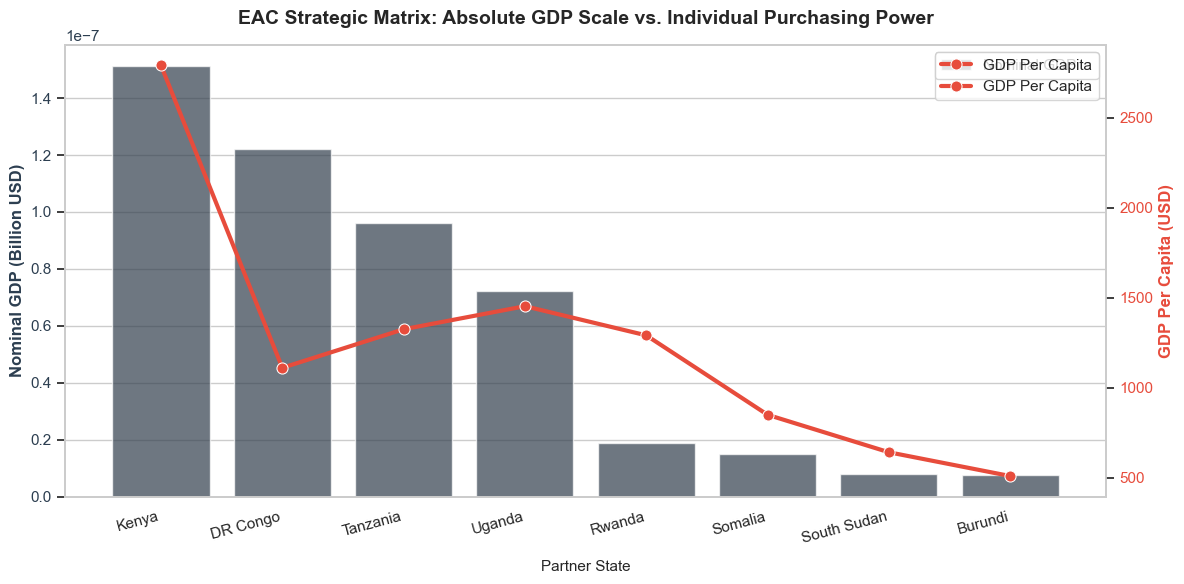

In [7]:
# Setup professional visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
countries_sorted = gdp.sort_values(by="Nominal GDP (Billion USD)", ascending=False)

fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

# Plot Absolute GDP (Bars)
sns.barplot(
    x="Country",
    y=countries_sorted["Nominal GDP (Billion USD)"] / 1e9,
    data=countries_sorted,
    alpha=0.7,
    color="#2c3e50",
    ax=ax1,
    label="Nominal GDP",
)
ax1.set_ylabel("Nominal GDP (Billion USD)", color="#2c3e50", weight="bold")
ax1.tick_params(axis="y", labelcolor="#2c3e50")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=15, ha="right")

# Plot GDP Per Capita (Line)
sns.lineplot(
    x="Country",
    y="GDP per Capita (Nominal USD)",
    data=countries_sorted,
    color="#e74c3c",
    marker="o",
    linewidth=3,
    markersize=8,
    ax=ax2,
    label="GDP Per Capita",
)
ax2.set_ylabel("GDP Per Capita (USD)", color="#e74c3c", weight="bold")
ax2.tick_params(axis="y", labelcolor="#e74c3c")
ax2.grid(False)

plt.title(
    "EAC Strategic Matrix: Absolute GDP Scale vs. Individual Purchasing Power",
    fontsize=14,
    weight="bold",
    pad=15,
)
ax1.set_xlabel("Partner State", fontsize=11, labelpad=10)

# Unify Legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

fig.tight_layout()
plt.show()

### Core Analytical Observations:

#### 1. Kenya Combines Market Scale and Relative Purchasing Power:
Kenya leads this comparison in nominal GDP (USD 151.15 billion) and GDP per capita (USD 2,790). That mix is a stronger potential base for EV financing and charging investment than aggregate GDP alone, though national averages do not establish household affordability.

#### 2. DR Congo?s Large Economy Does Not Mean Broad Affordability:
DR Congo has the second-largest GDP (USD 122.28 billion) and the largest population (116.4 million), but GDP per capita is USD 1,111. It offers potential commercial fleet scale while suggesting that mass private-car adoption may face affordability constraints.

#### 3. Smaller and Lower-Income Markets Need Different Entry Points:
Burundi and South Sudan record the lowest GDP per capita in this dataset (USD 510 and USD 642). Tanzania and Uganda have larger aggregate economies but per-capita figures below USD 1,500.

#### 4. Bar-Scale Caveat:
The plotted GDP values are already in billion USD, but the chart divides them by 1e9 again. The ranking remains visible, but the bar-axis magnitudes are not in the intended scale; use the source table for comparisons until the conversion is corrected.

### Strategic Policy Insights:

#### 1. Fit EV Finance to Use Case and Income:
Prioritize leasing, pay-as-you-drive, and battery-as-a-service models for commercial vehicles where upfront purchase costs are difficult to absorb. Validate these models against local income and operating-cost data.

#### 2. Phase Charging Investment Against Demonstrated Demand:
Use GDP as a screening measure, not a demand forecast. Combine it with registrations, fleet routes, electricity tariffs, access to finance, and grid reliability before committing capital.


In [8]:
gdp.columns

Index(['Country', 'Nominal GDP (Billion USD)', 'GDP per Capita (Nominal USD)',
       'Estimated Population (Million)', 'Source / Verification'],
      dtype='object')

In [11]:
power = pd.read_csv('EAC Power and energy distribution.csv')
power

,Country,Annual Generation (kWh),Installed Capacity (MW),Peak Demand (MW),Population Access (%),Hydro Share (%),Fossil Share (%),Other Renewables (%),Primary Verifiable Data Sources
0,DR Congo,15920000000,2516,2174,22.5,98.20,1.10,0.70,World Bank Mission 300 Network; EAPP Regional ...
1,Kenya,13260000000,3840,2514,77.0,22.65,8.34,69.01,EPRA Energy & Petroleum Statistics; Low-Carbon...
2,Tanzania,8850000000,4646,1944,52.4,61.45,31.85,6.70,EWURA Sub-Sector Performance Review; TanzaniaI...
3,Uganda,5410000000,1718,1176,50.1,90.40,2.90,6.70,EREA Electricity Portfolio Review; IEA Uganda ...
4,Rwanda,1040000000,320,262,54.0,42.00,23.00,35.00,World Bank RETRADE-EA Regional Portfolios; ERE...
5,South Sudan,540000000,130,65,5.4,0.00,94.60,5.40,World Bank SDG 7.1.1 Access Indicator; EAPP Gr...
6,Somalia,390000000,115,60,15.0,0.00,82.00,18.00,World Bank Horn of Africa Integration Briefs; ...
7,Burundi,380000000,95,70,20.1,78.50,14.50,7.00,World Bank Mission 300 Rural Interventions; EA...


In [12]:
power.columns

Index(['Country', 'Annual Generation (kWh)', 'Installed Capacity (MW)',
       'Peak Demand (MW)', 'Population Access (%)', 'Hydro Share (%)',
       'Fossil Share (%)', 'Other Renewables (%)',
       'Primary Verifiable Data Sources'],
      dtype='object')

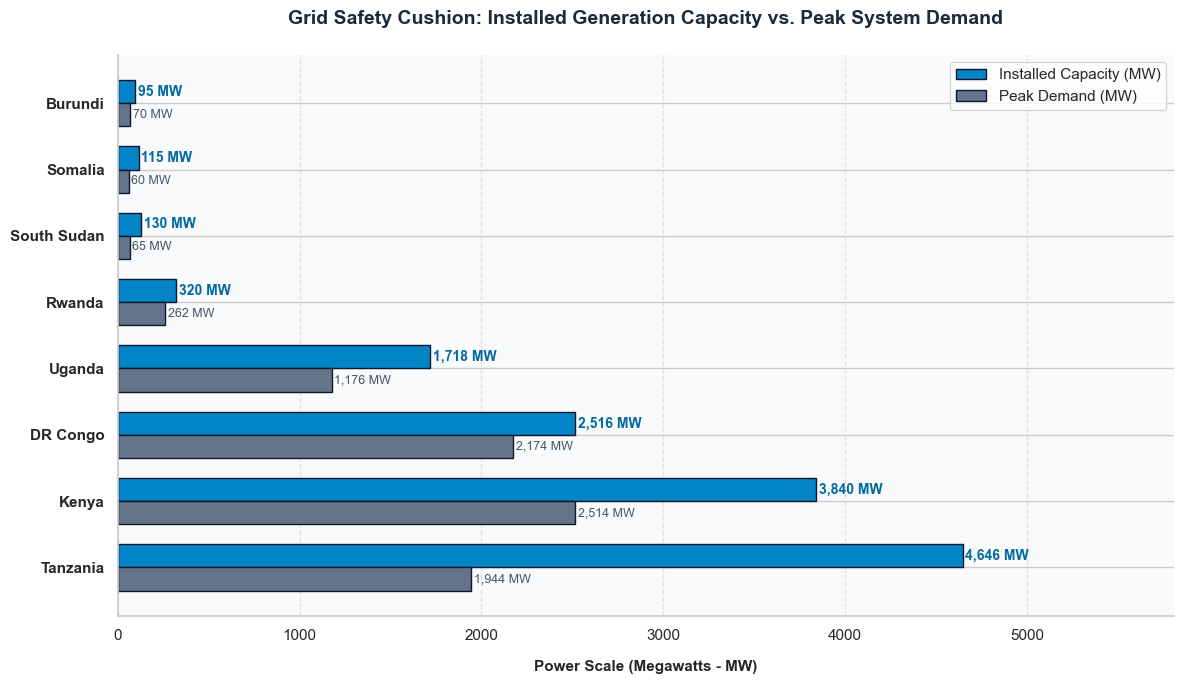

In [16]:
# Ensure your variable is sorted by absolute installed capacity scale
power = power.sort_values(by='Installed Capacity (MW)', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7), dpi=100)
ax.set_facecolor('#F8FAFC')

y_indices = np.arange(len(power))
bar_height = 0.35

# Plot Installed Capacity vs. Active Peak Demand side-by-side
bars_cap = ax.barh(y_indices + bar_height/2, power['Installed Capacity (MW)'], bar_height, 
                    label='Installed Capacity (MW)', color='#0284C7', edgecolor='#0F172A')
bars_peak = ax.barh(y_indices - bar_height/2, power['Peak Demand (MW)'], bar_height, 
                     label='Peak Demand (MW)', color='#64748B', edgecolor='#0F172A')

# Add numeric value annotations on top of the bars for non-tech clarity
for bar in bars_cap:
    ax.text(bar.get_width() + 15, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width()):,} MW", 
            va='center', ha='left', color='#0369A1', weight='bold', size=10)

for bar in bars_peak:
    ax.text(bar.get_width() + 15, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width()):,} MW", 
            va='center', ha='left', color='#475569', size=9)

ax.set_title('Grid Safety Cushion: Installed Generation Capacity vs. Peak System Demand', fontsize=14, pad=22, weight='bold', color='#1E293B')
ax.set_xlabel('Power Scale (Megawatts - MW)', fontsize=11, labelpad=12, weight='semibold')
ax.set_yticks(y_indices)


ax.set_yticklabels(power['Country'], fontsize=11, weight='bold')

ax.set_xlim(0, power['Installed Capacity (MW)'].max() * 1.25)
ax.legend(loc='upper right', frameon=True, facecolor='white')
for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



### Core Analytical Observations:

#### 1. Installed Capacity Exceeds Reported Peak Demand in Every Country:
The largest absolute capacity is Tanzania?s 4,646 MW, while Kenya has 3,840 MW and DR Congo 2,516 MW. Tanzania?s installed capacity is about 2.4 times its reported peak demand; Burundi?s is about 1.4 times. These are nameplate comparisons, not proof that the capacity is continuously available.

#### 2. Some Markets Have Limited Nominal Headroom:
Rwanda reports 320 MW against 262 MW peak demand, and DR Congo 2,516 MW against 2,174 MW. Such relatively narrow margins could make additional charging loads more sensitive to plant outages, seasonal hydrology, and network bottlenecks.

#### 3. Installed Capacity Alone Does Not Determine Charging Reliability:
South Sudan?s 130 MW versus 65 MW demand appears to show headroom, yet low electricity access and a generation mix dominated by fossil fuels point to broader supply and distribution challenges.

### Strategic Policy Insights:

#### 1. Assess Firm, Deliverable Capacity Before Siting High-Power Chargers:
Pair capacity-demand ratios with outage records, transmission constraints, reserve margins, and distribution feeder studies. Do not treat the difference between installed capacity and peak demand as guaranteed spare power.

#### 2. Coordinate EV Load Growth with Grid Planning:
Require charging hubs and depots to submit phased load forecasts, use managed charging, and consider on-site storage or backup where reliability studies show a material risk.


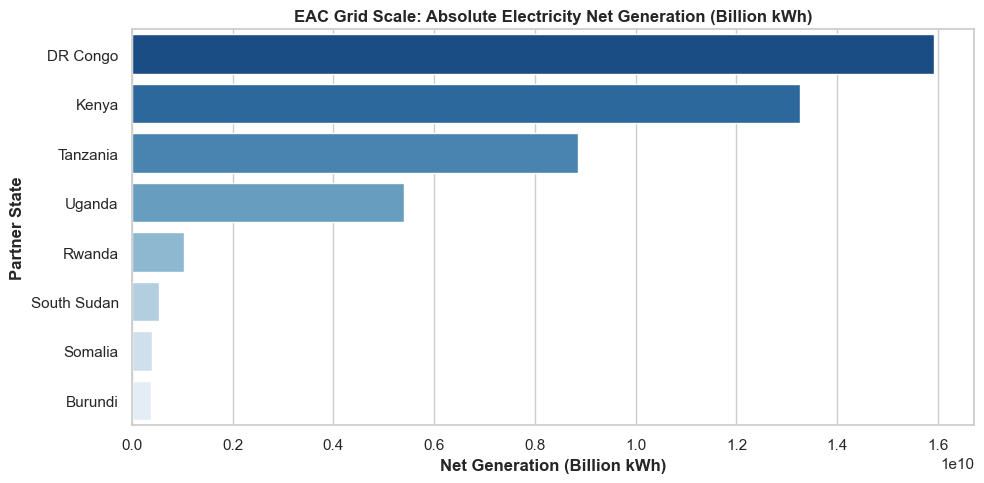

In [23]:
# Sort directly on your existing egc dataset for clean visualization
egc_sorted_gen = power.sort_values(by="Annual Generation (kWh)", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(
    x="Annual Generation (kWh)", y="Country", 
    data=egc_sorted_gen, palette="Blues_r", hue="Country", legend=False
)
plt.title("EAC Grid Scale: Absolute Electricity Net Generation (Billion kWh)", fontweight='bold')
plt.xlabel("Net Generation (Billion kWh)",fontweight='bold')
plt.ylabel("Partner State", fontweight='bold')


plt.tight_layout()
plt.show()

### Core Analytical Observations:

#### 1. DR Congo and Kenya Lead Absolute Generation:
The dataset reports annual generation of 15.92 billion kWh for DR Congo and 13.26 billion kWh for Kenya. Tanzania follows at 8.85 billion kWh, with Uganda at 5.41 billion kWh. These markets have the largest reported electricity volumes for supporting scaled transport electrification.

#### 2. Smaller Systems Have Much Less Aggregate Supply:
Rwanda, South Sudan, Somalia, and Burundi are reported below 1.1 billion kWh each. National totals conceal local congestion and unequal access, so they cannot by themselves establish the viability of a particular charging site.

#### 3. Unit Caveat:
The chart plots raw kWh values while labeling the axis in billion kWh. Its country ranking is still informative, but interpret magnitudes from the source data until the axis is converted or relabeled.

### Strategic Policy Insights:

#### 1. Translate Vehicle Uptake into Localized Load Forecasts:
Estimate charging demand by fleet segment, route, time of day, and depot location, then compare it with local?not just national?generation and network capacity.

#### 2. Read the Axis Units Carefully:
The chart plots kWh values while its axis is labeled in billion kWh. The ranking remains useful, but the unit presentation should be corrected or interpreted cautiously before using the plotted magnitudes in an investment case.


In [26]:
types = pd.read_csv('EAC Power Energy Types.csv')
types

,Country,Hydropower (%),Fossil Fuels (%),Other Renewables (%),Average Cost (USD per kWh),Primary Verifiable Data Source
0,DR Congo,98.20,1.10,0.70,0.08,World Bank Mission 300 Network; EAPP Regional ...
1,Tanzania,61.45,31.85,6.70,0.10,EWURA Sub-Sector Performance Review; TanzaniaI...
2,Uganda,90.40,2.90,6.70,0.14,EREA Electricity Portfolio Review; IEA Uganda ...
3,Burundi,78.50,14.50,7.00,0.16,World Bank Mission 300 Rural Interventions; EA...
4,Rwanda,42.00,23.00,35.00,0.19,World Bank RETRADE-EA Regional Portfolios; ERE...
5,Kenya,22.65,8.34,69.01,0.24,EPRA Energy & Petroleum Statistics; Low-Carbon...
6,South Sudan,0.00,94.60,5.40,0.39,World Bank SDG 7.1.1 Access Indicator; EAPP Gr...
7,Somalia,0.00,82.00,18.00,0.52,World Bank Horn of Africa Integration Briefs; ...


In [27]:
types.columns

Index(['Country', 'Hydropower (%)', 'Fossil Fuels (%)', 'Other Renewables (%)',
       'Average Cost (USD per kWh)', 'Primary Verifiable Data Source'],
      dtype='object')

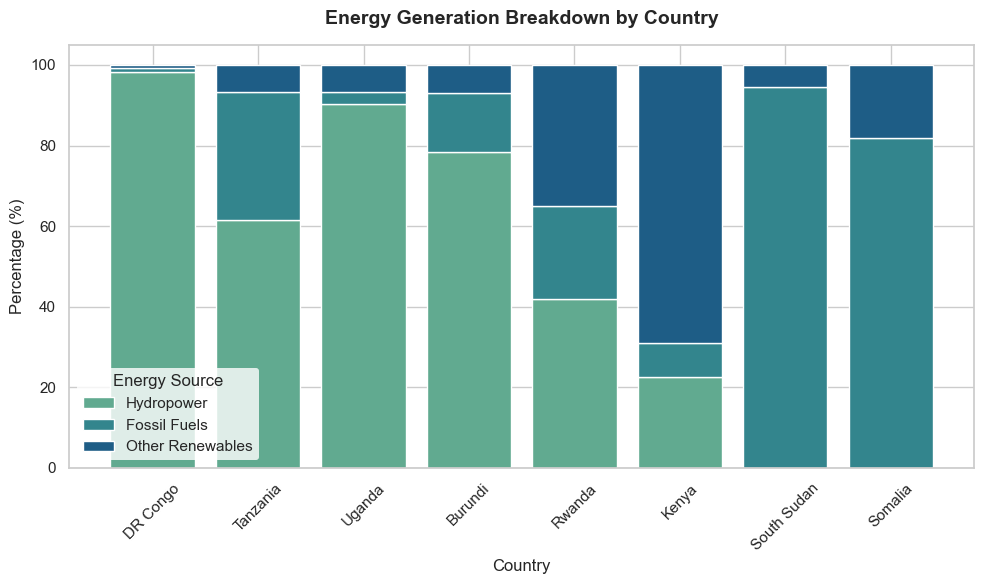

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract 3 harmonious colors from the 'crest' palette
colors = sns.color_palette("crest", 3)

plt.figure(figsize=(10, 6))

# Plot stacked bars with the soft palette
plt.bar(types['Country'], types['Hydropower (%)'], label='Hydropower', color=colors[0])
plt.bar(types['Country'], types['Fossil Fuels (%)'], bottom=types['Hydropower (%)'], label='Fossil Fuels', color=colors[1])
plt.bar(types['Country'], types['Other Renewables (%)'], 
        bottom=types['Hydropower (%)'] + types['Fossil Fuels (%)'], label='Other Renewables', color=colors[2])

# Labels and styling
plt.title('Energy Generation Breakdown by Country', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Energy Source', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()

plt.show()



### Core Analytical Observations:

#### 1. Hydropower Dominates Several National Generation Mixes:
Hydropower is reported at 98.2% in DR Congo and 90.4% in Uganda, with Burundi at 78.5% and Tanzania at 61.45%. Such a mix can support low-carbon EV operation when the electricity is available at the charging location.

#### 2. Kenya and Rwanda Have More Diversified Renewable Profiles:
Kenya?s mix is led by other renewables (69.01%), while Rwanda reports 35% other renewables and 42% hydropower. South Sudan and Somalia have the highest fossil shares at 94.6% and 82%, respectively.

#### 3. National Mix Is Not the Same as Marginal Charging Emissions:
Actual EV charging emissions depend on when and where charging occurs, grid dispatch, and transmission losses, not only annual generation shares.

### Strategic Policy Insights:

#### 1. Align Charging with Clean Supply:
Prioritize daytime managed charging where solar is available, and evaluate renewable power purchase agreements and storage for fleet depots.

#### 2. Avoid Treating ?Renewable? as a Proxy for Reliable:
Pair clean-energy targets with utility service-quality measures and feeder-level planning so fleets receive both low-carbon and dependable energy.


C:\Users\PC\AppData\Local\Temp\ipykernel_18448\1002859521.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Country', y='Average Cost (USD per kWh)', data=types_sorted, palette='mako')


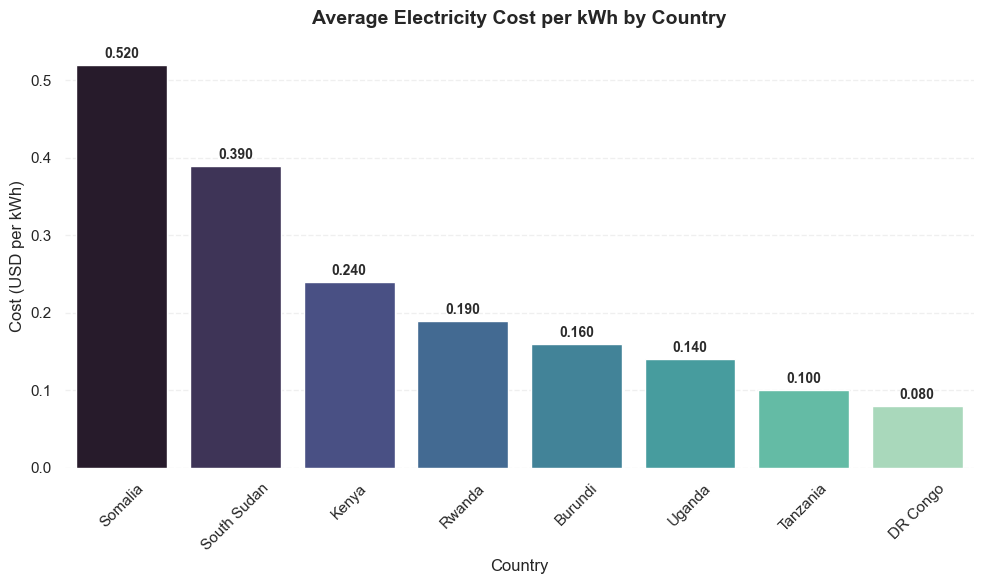

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Sort to make the gradient transition smoothly across the bars
types_sorted = types.sort_values(by='Average Cost (USD per kWh)', ascending=False)

# Generate bar chart with the appeasing 'mako' gradient
ax = sns.barplot(x='Country', y='Average Cost (USD per kWh)', data=types_sorted, palette='mako')

# Add the values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10, fontweight='bold', color='#2b2b2b')

# Labels and styling
plt.title('Average Electricity Cost per kWh by Country', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Cost (USD per kWh)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.3)  # Softened gridlines
sns.despine(left=True, bottom=True)             # Clean, borderless look
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Electricity Costs Vary Sharply Across the Sample:
The reported average ranges from USD 0.08/kWh in DR Congo and USD 0.10/kWh in Tanzania to USD 0.39 in South Sudan and USD 0.52 in Somalia. Kenya (USD 0.24/kWh) and Rwanda (USD 0.19/kWh) sit between these extremes.

#### 2. High Energy Costs Can Weaken EV Operating Savings:
At the reported rates, electricity expense can materially affect the cost advantage of electric motorcycles, buses, and commercial fleets?especially in high-mileage applications. The result will also depend on fuel prices, vehicle efficiency, and charging losses.

### Strategic Policy Insights:

#### 1. Compare Like-for-Like Tariffs and Total Cost of Ownership:
Before setting charging tariffs or estimating payback, verify whether these averages represent household, commercial, or industrial supply and include applicable taxes, demand charges, and time-of-use rates.

#### 2. Target Cost Relief Where It Unlocks Utilization:
Consider dedicated e-mobility tariffs and off-peak charging for high-utilization fleets, while protecting utility cost recovery and monitoring whether savings reach operators and drivers.


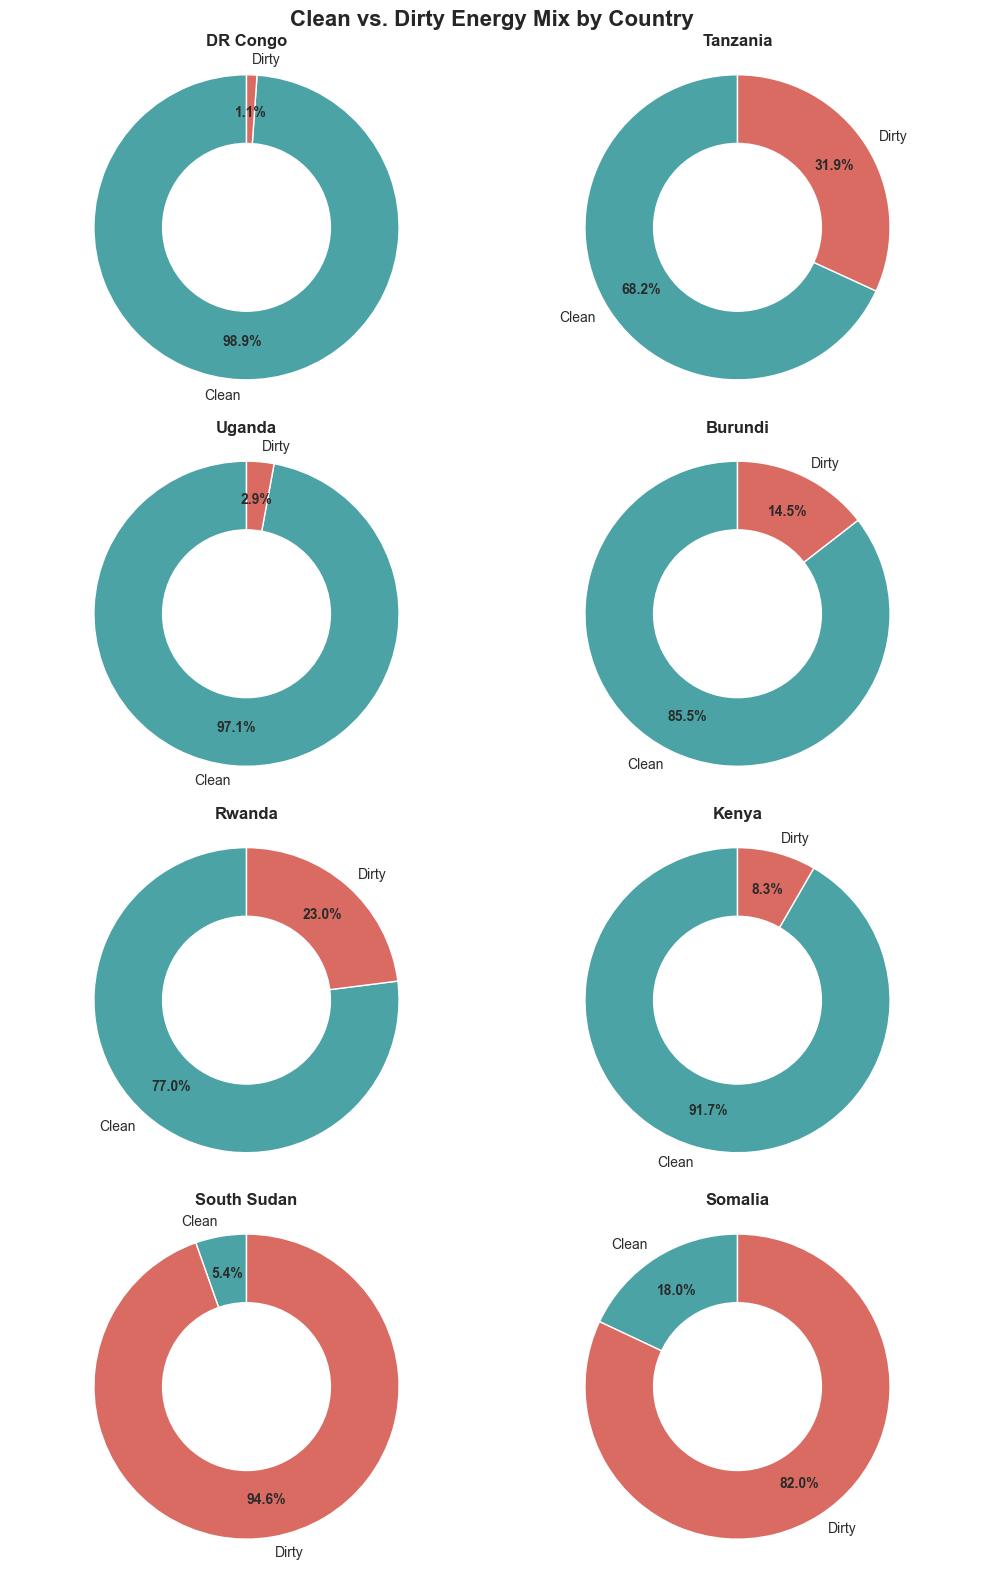

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# 1. First, make sure the clean and dirty columns are calculated
types['Clean Energy (%)'] = types['Hydropower (%)'] + types['Other Renewables (%)']
types['Dirty Energy (%)'] = types['Fossil Fuels (%)']

# 2. Setup the subplot grid dynamically based on the number of countries
num_countries = len(types)
# Create a grid: 2 columns, and as many rows as needed
ncols = 2
nrows = int(np.ceil(num_countries / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10, 4 * nrows))
axes = axes.flatten()  # Flatten to a 1D array for easy looping

# Soft, appeasing colors for Clean vs. Dirty
colors = ['#4ba3a5', '#d96b62'] 

# 3. Loop through each country and build its donut plot
for i, (idx, row) in enumerate(types.iterrows()):
    ax = axes[i]
    
    # Extract data for the current country
    sizes = [row['Clean Energy (%)'], row['Dirty Energy (%)']]
    labels = ['Clean', 'Dirty']
    
    # Filter out 0% categories to keep the visual clean
    non_zero_indices = [j for j, val in enumerate(sizes) if val > 0]
    filtered_sizes = [sizes[j] for j in non_zero_indices]
    filtered_labels = [labels[j] for j in non_zero_indices]
    filtered_colors = [colors[j] for j in non_zero_indices]
    
    # Plot the outer pie slice
    wedges, texts, autotexts = ax.pie(
        filtered_sizes, 
        labels=filtered_labels,
        autopct='%1.1f%%', 
        startangle=90, 
        colors=filtered_colors,
        textprops=dict(color="#2b2b2b", fontsize=10),
        pctdistance=0.75  # Position percentages nicely inside the donut slice
    )
    
    # Make percentages bold and clean
    for autotext in autotexts:
        autotext.set_fontweight('bold')
        
    # Draw the inner circle to create the "donut" hole
    centre_circle = plt.Circle((0, 0), 0.55, fc='white')
    ax.add_artist(centre_circle)
    
    # Subplot styling
    ax.set_title(row['Country'], fontsize=12, fontweight='bold', pad=10)
    ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# 4. Hide any unused subplot squares if the number of countries is odd
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Layout adjustments
plt.suptitle('Clean vs. Dirty Energy Mix by Country', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### Core Analytical Observations:

#### 1. Clean Generation Shares Are High in Several Countries:
Using hydropower plus other renewables as the clean share, DR Congo is at 98.9%, Uganda at 97.1%, Burundi at 85.5%, and Kenya at 91.66%. Tanzania is at 68.15% and Rwanda at 77% in the supplied dataset.

#### 2. South Sudan and Somalia Have the Most Carbon-Intensive Mixes:
Their reported clean shares are 5.4% and 18%, respectively, with fossil fuels providing most generation. Electrification in these systems can still reduce urban tailpipe pollution, but its climate benefit depends on grid decarbonization and charging efficiency.

### Strategic Policy Insights:

#### 1. Track Transport Electrification and Power-Sector Decarbonization Together:
Report EV uptake alongside charging-time emissions and renewable generation growth so that climate claims reflect the electricity actually used.

#### 2. Use Distributed Renewables Strategically:
Solar-plus-storage at depots and swapping stations can reduce exposure to fossil-heavy or unreliable grids, subject to site-specific technical and economic assessment.


In [41]:
access = pd.read_csv('east_africa_electricity_analysis.csv')
access

,Country,Total National Access (%),Urban Access (%),Rural Access (%),The Access Gap (%)
0,Kenya,77.0,94.0,68.2,25.8
1,Rwanda,54.0,91.5,64.0,27.5
2,Uganda,50.1,78.1,32.4,45.7
3,Tanzania,52.4,84.6,37.8,46.8
4,Burundi,20.1,51.8,4.9,46.9
5,Somalia,15.0,54.0,6.5,47.5
6,DR Congo,22.5,55.0,1.0,54.0
7,South Sudan,5.4,22.8,0.7,22.1


In [42]:
access.columns

Index(['Country', 'Total National Access (%)', 'Urban Access (%)',
       'Rural Access (%)', 'The Access Gap (%)'],
      dtype='object')

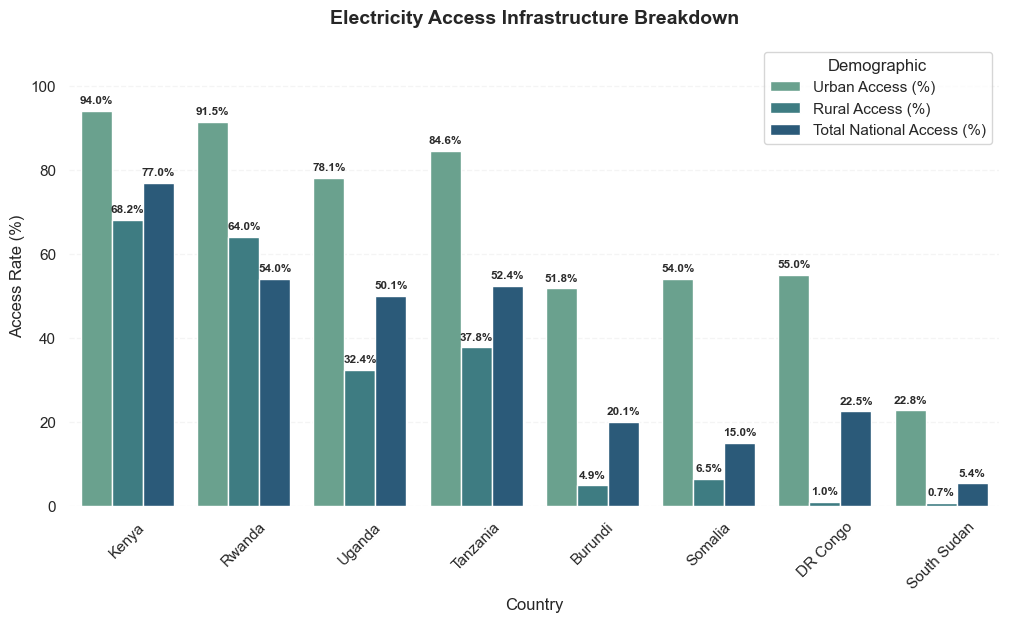

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Melt the dataframe to make it compatible with Seaborn's grouped bar formatting
access_melted = pd.melt(
    access, 
    id_vars=['Country'], 
    value_vars=['Urban Access (%)', 'Rural Access (%)', 'Total National Access (%)'],
    var_name='Access Type', 
    value_name='Percentage (%)'
)

plt.figure(figsize=(12, 6))

# Generate the grouped bar plot with an appeasing palette
ax = sns.barplot(
    x='Country', 
    y='Percentage (%)', 
    hue='Access Type', 
    data=access_melted, 
    palette='crest'
)

# Optional: Add small text labels on top of the bars for clarity
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=4, fontsize=8.5, fontweight='bold', color='#2b2b2b')
# Styling and clean borders
plt.title('Electricity Access Infrastructure Breakdown', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Access Rate (%)', fontsize=12)
plt.xticks(rotation=45)
plt.ylim(0, 110)  # Extra room for the text labels
plt.legend(title='Demographic', loc='upper right', frameon=True)
sns.despine(left=True, bottom=True)
plt.grid(axis='y', linestyle='--', alpha=0.2)


plt.show()


### Core Analytical Observations:

#### 1. National Electricity Access Is Uneven:
Kenya has the highest reported national access (77%), followed by Rwanda (54%), Tanzania (52.4%), and Uganda (50.1%). South Sudan is lowest at 5.4%; Somalia and Burundi are also below 21%.

#### 2. Urban Access Outpaces Rural Access:
Urban access reaches 94% in Kenya and 91.5% in Rwanda, but rural access is only 68.2% and 64%. Rural access is particularly limited in DR Congo (1%), South Sudan (0.7%), Burundi (4.9%), and Somalia (6.5%).

#### 3. Access Shapes Where Charging Can Scale First:
The gap implies that grid-tied public charging is more immediately feasible in urban centers and major corridors than in many rural areas; it does not rule out distributed or off-grid charging.

### Strategic Policy Insights:

#### 1. Expand Along High-Utilization Corridors First:
Prioritize urban depots, transport hubs, and intercity routes where grid access and vehicle throughput can support utilization, while planning rural pilots around local demand.

#### 2. Include Energy Access in Equity Measures:
Pair charging-network targets with rural electrification and affordability metrics so EV deployment does not concentrate benefits only in already connected urban areas.


C:\Users\PC\AppData\Local\Temp\ipykernel_18448\3204046796.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


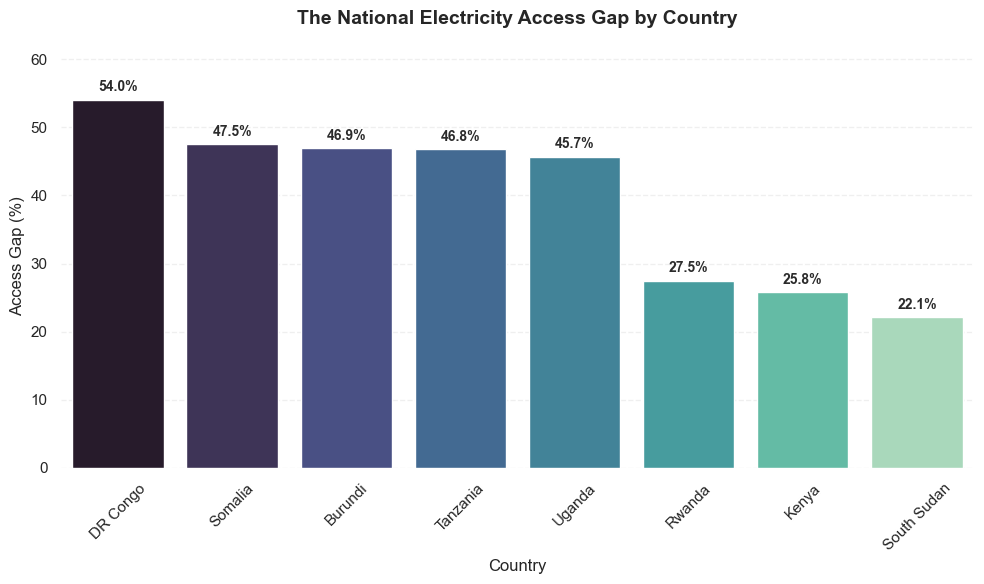

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Sort the data so the gradient transitions smoothly from largest gap to smallest
access_sorted = access.sort_values(by='The Access Gap (%)', ascending=False)

# Generate the bar chart
ax = sns.barplot(
    x='Country', 
    y='The Access Gap (%)', 
    data=access_sorted, 
    palette='mako'
)

# Print the precise percentage values on top of each bar graph
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=4, fontsize=10, fontweight='bold', color='#2b2b2b')

# Labels and styling
plt.title('The National Electricity Access Gap by Country', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Access Gap (%)', fontsize=12)
plt.xticks(rotation=45)
plt.ylim(0, access_sorted['The Access Gap (%)'].max() * 1.15) # Adjust headroom dynamically
plt.grid(axis='y', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. The Urban-Rural Divide Is a Critical Deployment Constraint:
DR Congo has the largest reported access gap (54 percentage points), while Tanzania, Uganda, Burundi, and Somalia all show gaps of roughly 46?48 points. Kenya and Rwanda have smaller?but still substantial?gaps of 25.8 and 27.5 points.

#### 2. The Lowest Rural Access Is in South Sudan and DR Congo:
Rural access is 0.7% in South Sudan and 1% in DR Congo, compared with urban access of 22.8% and 55%. This limits the reach of conventional grid-dependent charging beyond established service areas.

### Strategic Policy Insights:

#### 1. Plan Rural Charging Around Local Energy Systems:
Assess solar mini-grids, storage, and shared charging or swapping hubs where grid extension is not yet viable. Size these pilots to actual transport demand and maintenance capacity.

#### 2. Track Both Access Levels and the Gap:
A rising national average can conceal stagnant rural access. Monitor rural and urban access separately when evaluating the inclusiveness of e-mobility corridors.


In [55]:
vehicles = pd.read_csv('EAC_EV_ICE_Segment_Matrix_2026.csv')
vehicles

,Country,Propulsion Type,2-Wheelers (2W),3-Wheelers (3W),Public Buses,Passenger / Commercial,Private Vehicles,Total,Data Source
0,Kenya,EV,36970.0,1180,750,248,176,39324,National Transport and Safety Authority (NTSA)...
1,Kenya,ICE,1550000.0,110000,105000,64000,820000,3225000,National Transport and Safety Authority (NTSA)...
2,Uganda,EV,31850.0,540,480,90,40,33000,Ministry of Works and Transport & Uganda Reven...
3,Uganda,ICE,1120000.0,42000,68000,215000,440000,1885000,Ministry of Works and Transport & Uganda Reven...
4,Rwanda,EV,6120.0,190,110,35,45,6500,Rwanda Utilities Regulatory Authority (RURA) F...
5,Rwanda,ICE,165000.0,14000,12000,41000,78000,310000,Rwanda Utilities Regulatory Authority (RURA) F...
6,Tanzania,EV,1250.0,3840,45,35,30,5200,Tanzania Revenue Authority (TRA) & Land Transp...
7,Tanzania,ICE,980000.0,185000,120000,460000,680000,2425000,Tanzania Revenue Authority (TRA) & Land Transp...
8,DR Congo,EV,110.0,0,25,320,45,500,Ministry of Transport (DRC) & EAC Corridor Dia...
9,DR Congo,ICE,440000.0,65000,95000,880000,1120000,2600000,Ministry of Transport (DRC) & EAC Corridor Dia...


In [56]:
vehicles.columns

Index(['Country', 'Propulsion Type', '2-Wheelers (2W)', '3-Wheelers (3W)',
       'Public Buses', 'Passenger / Commercial', 'Private Vehicles', 'Total',
       'Data Source'],
      dtype='object')

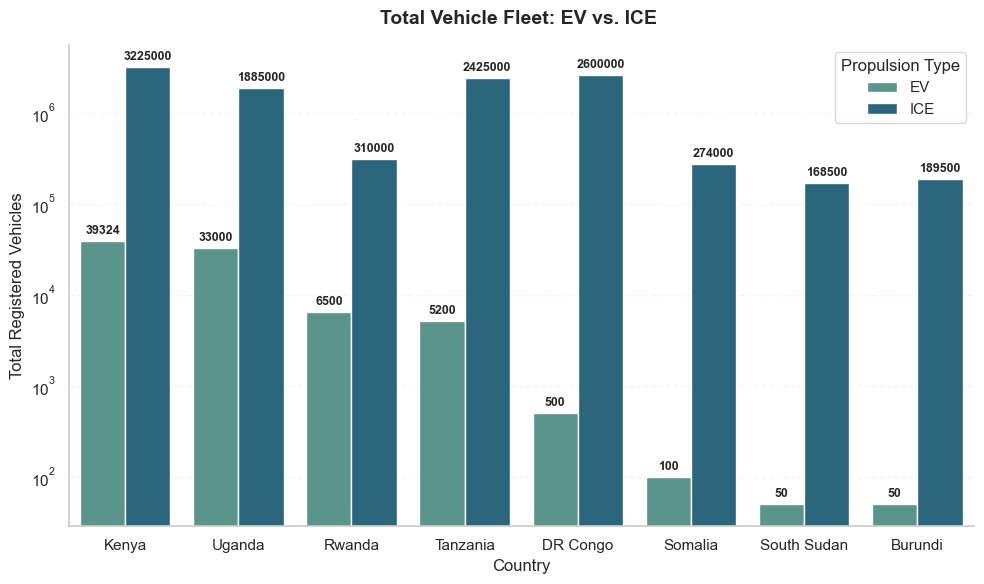

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot total fleet comparison
ax = sns.barplot(
    x='Country', 
    y='Total', 
    hue='Propulsion Type', 
    data=vehicles, 
    palette='crest'
)

# Use logarithmic scale because ICE heavily dominates EV numbers
plt.yscale('log')

# Add precise value labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9, fontweight='bold')

# Styling
plt.title('Total Vehicle Fleet: EV vs. ICE ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Total Registered Vehicles', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.2)
sns.despine()
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Electric Fleets Are Growing from a Small Base:
The chart compares totals on a logarithmic scale because ICE fleets remain much larger. Kenya has the largest listed EV fleet (39,324), followed by Uganda (33,000), while ICE totals range from 168,500 in South Sudan to 3.225 million in Kenya.

#### 2. The Relative Transition Differs by Country:
Using the table totals, EVs are approximately 2.1% of the combined Rwanda fleet and 1.7% in Uganda, versus about 1.2% in Kenya. Tanzania?s 5,200 EVs remain a small share of its 2.425 million ICE vehicles.

### Strategic Policy Insights:

#### 1. Measure Transition Progress with Multiple Indicators:
Report absolute EV stock, EV share of registered vehicles, annual additions, and vehicle segment. A logarithmic chart helps compare both propulsion types but can visually understate the absolute ICE-EV gap.

#### 2. Prioritize Segments with Existing Uptake:
Support two-wheelers and commercial fleets where adoption is already strongest, alongside reliable charging and battery services.


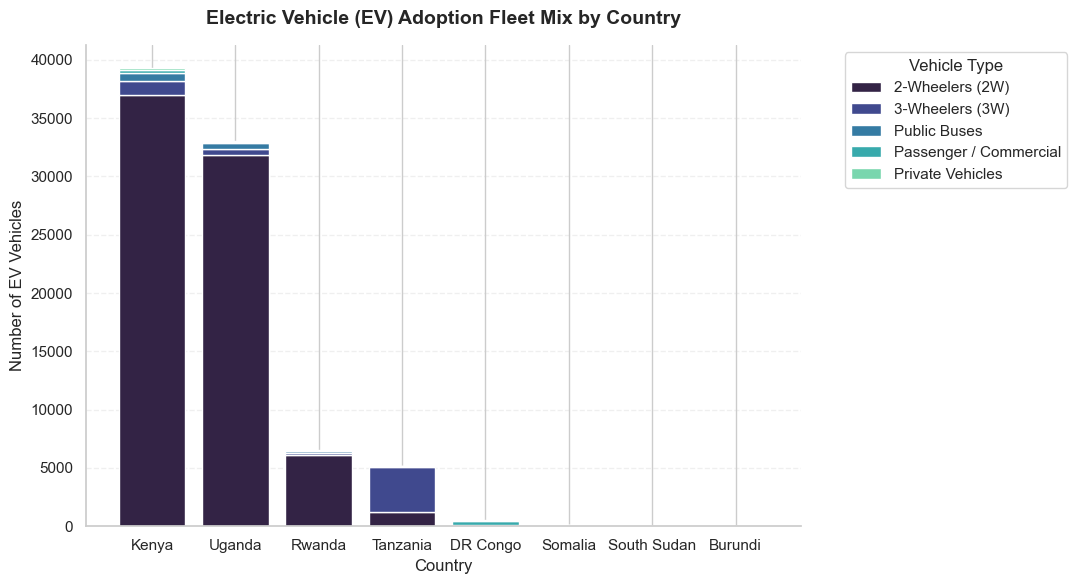

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter data to only look at Electric Vehicles (EV)
ev_data = vehicles[vehicles['Propulsion Type'] == 'EV'].copy()

# Select the columns representing vehicle segments
segments = ['2-Wheelers (2W)', '3-Wheelers (3W)', 'Public Buses', 'Passenger / Commercial', 'Private Vehicles']
colors = sns.color_palette("mako", len(segments))

plt.figure(figsize=(11, 6))

# Build stacked bars sequentially
bottoms = None
for i, segment in enumerate(segments):
    if bottoms is None:
        plt.bar(ev_data['Country'], ev_data[segment], label=segment, color=colors[i])
        bottoms = ev_data[segment].values
    else:
        plt.bar(ev_data['Country'], ev_data[segment], bottom=bottoms, label=segment, color=colors[i])
        bottoms += ev_data[segment].values

# Layout and labels
plt.title('Electric Vehicle (EV) Adoption Fleet Mix by Country', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of EV Vehicles', fontsize=12)
plt.legend(title='Vehicle Type', frameon=True, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)
sns.despine()
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Electric Two-Wheelers Anchor Current Adoption:
Kenya lists 36,970 electric two-wheelers out of 39,324 EVs, and Uganda lists 31,850 out of 33,000. Rwanda?s listed EV fleet is also led by two-wheelers (6,120 of 6,500).

#### 2. Tanzania?s EV Mix Is Distinctly Three-Wheeler-Oriented:
Tanzania reports 3,840 electric three-wheelers among 5,200 EVs. This points to a different commercial opportunity in passenger and goods transport than the motorcycle-heavy fleets in Kenya, Uganda, and Rwanda.

#### 3. Bus and Private EV Counts Remain Small in Most Listed Fleets:
The segment breakdown indicates room to grow electrified public transport, delivery, and private light vehicles, but the current stock is concentrated in a narrow set of vehicle types.

### Strategic Policy Insights:

#### 1. Tailor Infrastructure to Fleet Composition:
Build swapping and light-duty charging around two- and three-wheelers; plan depot charging, route scheduling, and grid upgrades for buses and commercial vehicles.

#### 2. Report Segment-Specific Uptake Consistently:
Common registration definitions and regular updates will help distinguish real market change from differences in registry coverage.


In [64]:
inspection_rates = pd.read_csv('EAC_Inspection_Rates.csv')
inspection_rates

,Country,2-Wheelers (E-Motorcycles),3-Wheelers (E-Tricycles),Buses (E-Buses / PSVs),Private Use (Light Passenger EVs),Verified Data Source & Official References
0,Kenya,1.55,3.85,15.40,15.40,Kenya Law Traffic Rules: Legal Notice No. 13 o...
1,Rwanda,7.30,7.30,37.60,25.50,IremboGov Vehicle Inspection Portal: Managed v...
2,Uganda,13.60,13.60,32.65,32.65,Uganda Revenue Authority (URA) & UNBS: Nationa...
3,Tanzania,5.60,5.60,18.70,18.70,Tanzania Bureau of Standards (TBS): Under the ...


In [65]:
inspection_rates.columns

Index(['Country', '2-Wheelers (E-Motorcycles)', '3-Wheelers (E-Tricycles)',
       'Buses (E-Buses / PSVs)', 'Private Use (Light Passenger EVs)',
       'Verified Data Source & Official References'],
      dtype='object')

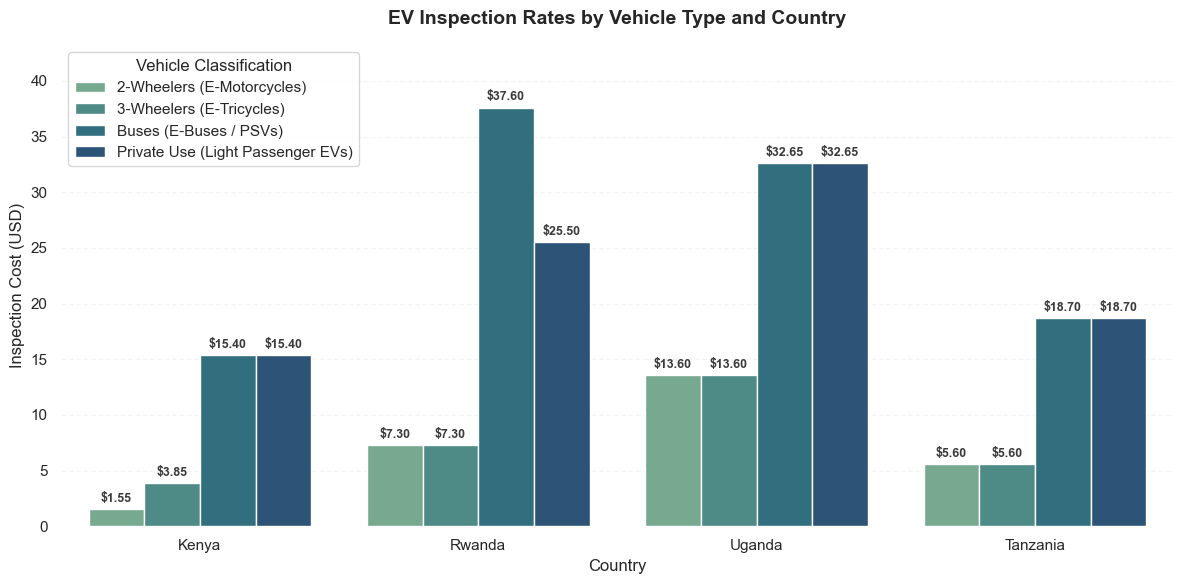

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Melt the dataframe to make it compatible with Seaborn's grouped bar formatting
rates_melted = pd.melt(
    inspection_rates, 
    id_vars=['Country'], 
    value_vars=['2-Wheelers (E-Motorcycles)', '3-Wheelers (E-Tricycles)', 'Buses (E-Buses / PSVs)', 'Private Use (Light Passenger EVs)'],
    var_name='Vehicle Type', 
    value_name='Inspection Rate (USD)'
)

plt.figure(figsize=(12, 6))

# Generate the grouped bar chart with an appeasing palette
ax = sns.barplot(
    x='Country', 
    y='Inspection Rate (USD)', 
    hue='Vehicle Type', 
    data=rates_melted, 
    palette='crest'
)

# Add exact USD values on top of each bar graph
for container in ax.containers:
    ax.bar_label(container, fmt='$%.2f', padding=3, fontsize=9, alpha=0.9, fontweight='bold')

# Labels and styling
plt.title('EV Inspection Rates by Vehicle Type and Country', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Inspection Cost (USD)', fontsize=12)
plt.xticks(rotation=0)  # Keep countries upright if names are short
plt.ylim(0, rates_melted['Inspection Rate (USD)'].max() * 1.15)  # Add headroom for labels
plt.legend(title='Vehicle Classification', loc='upper left', frameon=True)
sns.despine(left=True, bottom=True)
plt.grid(axis='y', linestyle='--', alpha=0.2)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Reported Inspection Charges Differ by Country and Vehicle Class:
In the plotted dataset, Rwanda has the highest listed bus inspection charge (USD 37.60). Uganda reports USD 32.65 for buses and private EVs, while Kenya reports USD 1.55 for two-wheelers and USD 15.40 for buses and private vehicles.

#### 2. Two- and Three-Wheeler Charges Are Often Lower Than Bus Charges:
Kenya reports USD 1.55 for e-motorcycles versus USD 15.40 for buses; Rwanda?s two- and three-wheeler rates are USD 7.30 compared with USD 37.60 for buses. These differences may affect fleet operating costs, especially for commercial vehicles inspected frequently.

### Strategic Policy Insights:

#### 1. Publish Transparent, Comparable EV Inspection Schedules:
Clarify whether amounts are per inspection, how often inspections are required, and whether battery or high-voltage checks are included.

#### 2. Keep Safety Standards while Avoiding Disproportionate Burdens:
Use risk-based inspection procedures and coordinate regional technical standards so operators can scale across borders without duplicative compliance costs.


In [67]:
charge = pd.read_csv('EAC_Top_charging_stations.csv')
charge

,Manufacturer,Country,Hub/Town Focus,Station Category,Approx. Network Count,Primary Station Access,Primary Verification Resource
0,Roam,Kenya,Nairobi,Swapping / Service Hubs,5,Public,Roam Infrastructure
1,BasiGo,Kenya,Nairobi,DC Fast Charging Depots,10,Commercial Fleet,BasiGo Charging
2,BasiGo,Rwanda,Kigali,DC Fast Charging Depots,2,Commercial Fleet,BasiGo Charging
3,Ampersand,Rwanda,Kigali,Automated Battery Swapping,15,Public,Ampersand Energy
4,Ampersand,Kenya,Nairobi,Automated Battery Swapping,12,Public,Ampersand Energy
5,Spiro,Kenya,Nairobi,Smart Battery Lockers,85,Public,Spiro Grid
6,Spiro,Rwanda,Kigali,Smart Battery Lockers,60,Public,Spiro Grid
7,Kiira Motors,Uganda,Jinja,Captive Fleet Chargers,2,Plant Testing,Kiira Motors Systems


In [68]:
charge.columns

Index(['Manufacturer', 'Country', 'Hub/Town Focus', 'Station Category',
       'Approx. Network Count', 'Primary Station Access',
       'Primary Verification Resource'],
      dtype='object')

C:\Users\PC\AppData\Local\Temp\ipykernel_18448\2575038181.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


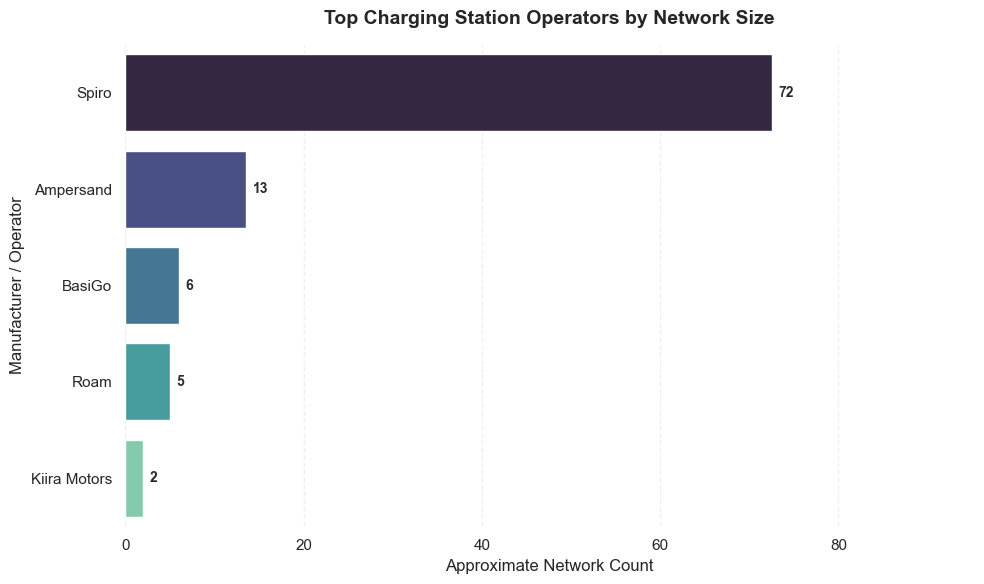

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Sort the networks from largest to smallest for a clean descending layout
charge_sorted = charge.sort_values(by='Approx. Network Count', ascending=False)

# Generate a clean, whisker-free horizontal bar chart
ax = sns.barplot(
    x='Approx. Network Count', 
    y='Manufacturer', 
    data=charge_sorted, 
    palette='mako',
    errorbar=None  # <-- Removes any calculated whiskers
)

# Print values cleanly at the tip of each horizontal bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=5, fontsize=10, fontweight='bold', color='#2b2b2b')

# Labels and styling
plt.title('Top Charging Station Operators by Network Size', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Approximate Network Count', fontsize=12)
plt.ylabel('Manufacturer / Operator', fontsize=12)
plt.xlim(0, charge_sorted['Approx. Network Count'].max() * 1.12)  # Create label breathing room
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.show()




### Core Analytical Observations:

#### 1. Listed Charging Assets Are Concentrated in a Few Operators:
The source records multiple country entries for some operators: Spiro lists 85 in Kenya and 60 in Rwanda; Ampersand lists 12 and 15; BasiGo lists 10 and 2. Roam lists 5 and Kiira Motors 2.

#### 2. The Chart?s Aggregation Can Obscure Total Network Size:
Because the same operator appears in more than one country and the chart uses a bar-plot average, its plotted value represents an average per listed row?not the operator?s combined total. Based on the supplied rows, Spiro?s listed total is 145 and Ampersand?s is 27.

### Strategic Policy Insights:

#### 1. Distinguish Public Access from Fleet- or Test-Only Infrastructure:
Count operational, publicly available charging and swapping points separately from commercial depots, captive fleet chargers, and plant-testing sites.

#### 2. Improve the Network Inventory:
Record precise location, connector or swap compatibility, uptime, power rating, public access, and last verification date. Aggregate counts by operator and country before comparing network scale.


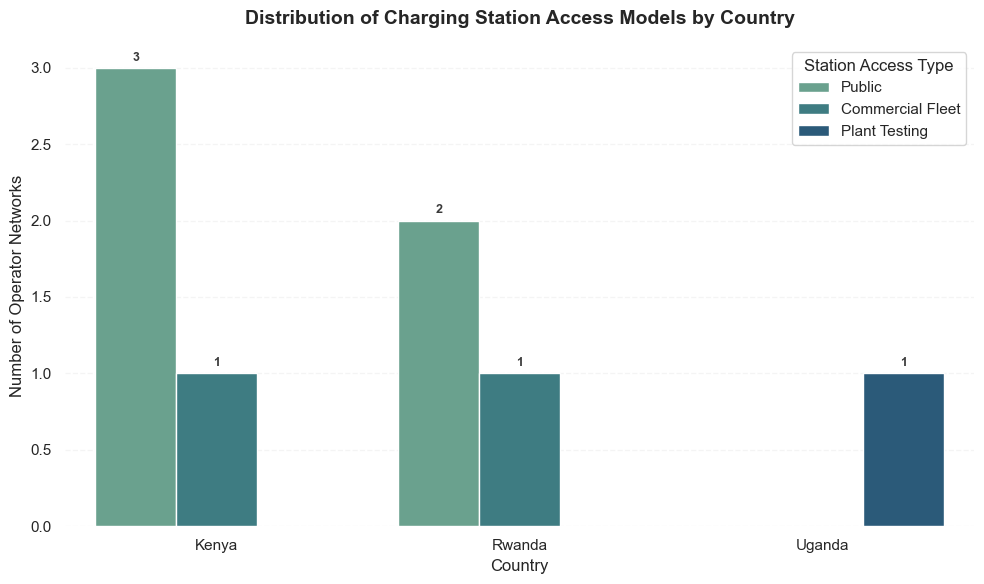

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Generate the categorical breakdown
ax = sns.countplot(
    x='Country', 
    hue='Primary Station Access', 
    data=charge, 
    palette='crest'
)

# Label the counts directly on top of each categorical cluster bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9, alpha=0.9, fontweight='bold')

# Labels and styling
plt.title('Distribution of Charging Station Access Models by Country', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Operator Networks', fontsize=12)
plt.legend(title='Station Access Type', loc='upper right', frameon=True)
sns.despine(left=True, bottom=True) # Completely borderless approach
plt.grid(axis='y', linestyle='--', alpha=0.2)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Recorded Access Models Cluster in Kenya and Rwanda:
The listed network records include public swap or locker services in Nairobi and Kigali, commercial fleet depots in both cities, and two captive plant-testing chargers in Jinja. Kenya and Rwanda therefore show the broadest mix of documented access types in this sample.

#### 2. Public Listings Do Not Equal Universal Availability:
The chart counts operator records by access category, not individual plugs, charging capacity, uptime, or geographic coverage. A public battery-swapping network also serves a different need from a public plug-in charger.

### Strategic Policy Insights:

#### 1. Build Around Interoperable, Clearly Labeled Access:
Publish whether each site is open to the public, limited to a contracted fleet, or for testing, and specify payment methods, hours, and compatible vehicles.

#### 2. Fill Gaps with Demand-Led Hubs:
Use route and utilization data to identify where additional public charging or swapping is needed beyond Nairobi and Kigali, while avoiding duplication of underused assets.


In [74]:
manufacturers = pd.read_csv('EAC_top_EV_manufacturers.csv')
manufacturers

,Manufacturer,Country,Primary Hub (Town),Vehicle Segment,Approx. Annual Capacity (Units),Number of Branches,Primary Model / Infrastructure,Official Website & Data Verification Source
0,Roam,Kenya,Nairobi,Motorcycles & Buses,50000,4,High local sourcing (40%+ content); direct veh...,Roam Official Site
1,Kiira Motors,Uganda,Jinja,Commercial Buses & Cars,5000,2,State-backed transit; domestic metallurgy focus,Kiira Motors Portal
2,Ampersand,Rwanda,Kigali,Motorcycles & Battery Packs,18000,15,Decoupled Pay-as-you-Go (PAYG) battery swappin...,Ampersand Energy Network
3,BasiGo,Kenya,Thika,Public Transport Buses,240,3,Pay-As-You-Drive real-time per-km mileage fina...,BasiGo Official Site
4,Spiro,Kenya,Nairobi,Motorcycles & Scooters,25000,22,Large-scale automated battery locker networks,Spiro African Network Deployment


In [75]:
manufacturers.columns

Index(['Manufacturer', 'Country', 'Primary Hub (Town)', 'Vehicle Segment',
       'Approx. Annual Capacity (Units)', 'Number of Branches',
       'Primary Model / Infrastructure',
       'Official Website & Data Verification Source'],
      dtype='object')

C:\Users\PC\AppData\Local\Temp\ipykernel_18448\482587588.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


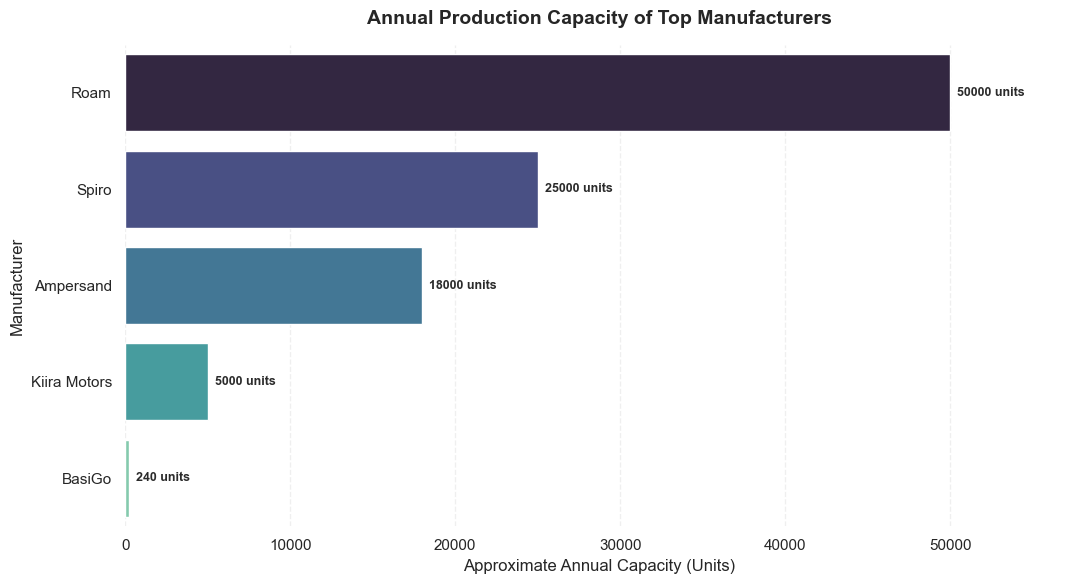

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

# Sort by capacity for a clean descending visualization layout
mfg_sorted = manufacturers.sort_values(by='Approx. Annual Capacity (Units)', ascending=False)

# Generate a clean, whisker-free horizontal bar chart
ax = sns.barplot(
    x='Approx. Annual Capacity (Units)', 
    y='Manufacturer', 
    data=mfg_sorted, 
    palette='mako',
    errorbar=None  # Completely removes whiskers
)

# Print precise capacity units at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d units', padding=5, fontsize=9, fontweight='bold', color='#2b2b2b')

# Labels and styling
plt.title('Annual Production Capacity of Top Manufacturers', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Approximate Annual Capacity (Units)', fontsize=12)
plt.ylabel('Manufacturer', fontsize=12)
plt.xlim(0, mfg_sorted['Approx. Annual Capacity (Units)'].max() * 1.15)  # Add label breathing room
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Annual Manufacturing Capacity Is Concentrated in Two-Wheelers:
The listed approximate capacity is 50,000 units for Roam, 25,000 for Spiro, and 18,000 for Ampersand. Together these three account for most of the 98,240 units of capacity listed across the five manufacturers; their products primarily address motorcycles, scooters, and battery packs.

#### 2. Bus and Broader Vehicle Production Is Smaller in the Dataset:
Kiira Motors lists capacity of 5,000, while BasiGo lists 240 buses annually. These figures describe different product categories and should not be read as equivalent output without clarifying what each unit count covers.

### Strategic Policy Insights:

#### 1. Connect Local Production to Fleet Procurement:
Use predictable public and commercial fleet orders, financing, and after-sales service to support sustainable utilization of local assembly capacity.

#### 2. Separate Installed Capacity from Actual Production:
Verify production achieved, component sourcing, workforce, and quality standards. Approximate nameplate capacity is not a measure of vehicles delivered or local value retained.


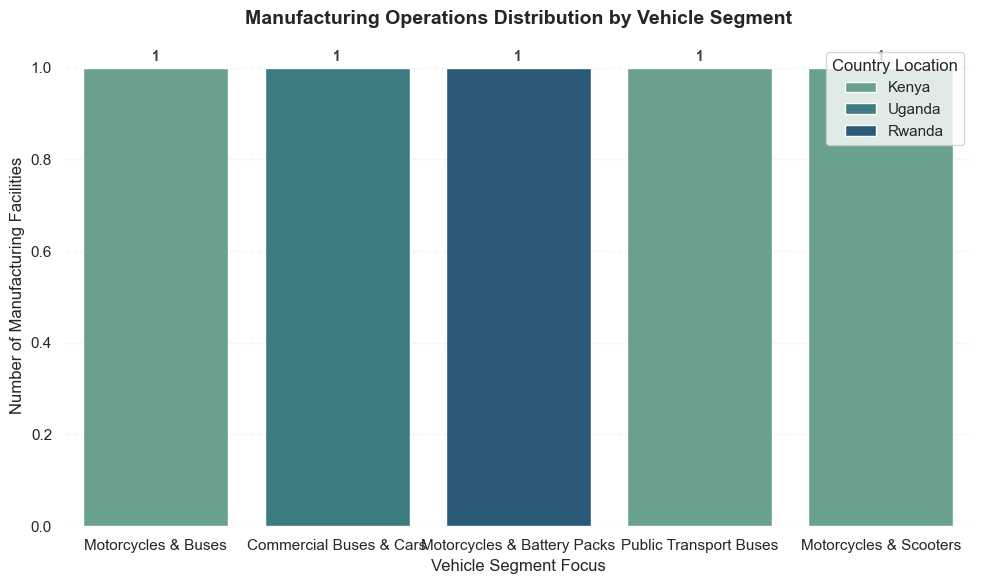

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot the setup distribution across segments
ax = sns.countplot(
    x='Vehicle Segment', 
    hue='Country', 
    data=manufacturers, 
    palette='crest'
)

# Place text numbers directly on top of each categorical category block
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=10, fontweight='bold', alpha=0.9)

# Labels and styling
plt.title('Manufacturing Operations Distribution by Vehicle Segment', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Vehicle Segment Focus', fontsize=12)
plt.ylabel('Number of Manufacturing Facilities', fontsize=12)
plt.legend(title='Country Location', loc='upper right', frameon=True)
sns.despine(left=True, bottom=True)
plt.grid(axis='y', linestyle='--', alpha=0.2)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Manufacturing Activity Is Focused in a Few Locations and Segments:
The listed manufacturers are based in Kenya, Rwanda, and Uganda. Motorcycle or scooter activity appears in Kenya and Rwanda, while buses are represented by Kenya- and Uganda-based manufacturers; the dataset also records battery-pack production.

#### 2. The Chart Counts Manufacturer Records, Not Facilities:
The plot uses a count chart over manufacturer rows, so its values indicate the number of listed company-segment records by country. They do not establish the number of physical factories, branches, or active production lines.

### Strategic Policy Insights:

#### 1. Strengthen Regional Supplier Linkages:
Support component standards, workforce training, and cross-border supply chains so local assembly can serve multiple EAC markets and vehicle segments.

#### 2. Improve Manufacturing Data Before Setting Targets:
Track operating plants, output by segment, local content, employment, and installed capacity separately. This enables more credible industrial-policy monitoring.


In [83]:
growth = pd.read_csv('EAC_Emobility_Growth_Rate.csv')
growth

,EAC Partner State,2020 Stock,2022 Stock,2024 Stock,2026 Stock (Mid-Year),Principal Sources & Structural Context
0,Kenya,300,1378,12500,39324,"NTSA Registers, Kenya E-Mobility Policy (2026)..."
1,Uganda,50,1200,7500,33000,IEA Global EV Outlook (2026) / Spiro Networks....
2,Tanzania,20,400,2500,10000,Agora Verkehrswende (2025). Dominated by e-tri...
3,Rwanda,30,520,2200,6500,"Rwanda MoE, Ampersand Trackers. Accelerated by..."
4,DR Congo (DRC),0,0,10,150,Afreximbank E-Mobility Mining Strategy. Fleet ...
5,Burundi,0,0,5,80,Burundi NDC Climate Actions Report (2025). Tra...
6,South Sudan,0,0,0,10,NCTTCA Northern Corridor GHG Baseline. Off-gri...
7,Somalia,0,0,0,5,EAC Logistical Strategy Placements (2026). Lim...


In [84]:
growth.columns

Index(['EAC Partner State', '2020 Stock', '2022 Stock', '2024 Stock',
       '2026 Stock (Mid-Year)', 'Principal Sources & Structural Context'],
      dtype='object')

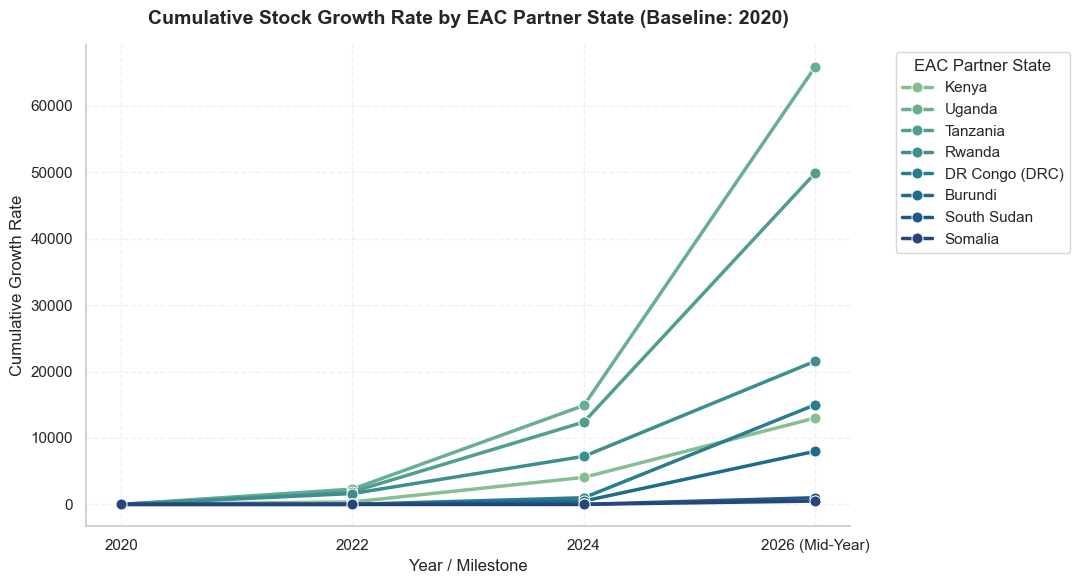

In [88]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the years/milestones in order
years = ['2020', '2022', '2024', '2026 (Mid-Year)']

# Calculate percentage growth relative to 2020 baseline for each country
plot_data = []
for idx, row in growth.iterrows():
    base = row['2020 Stock'] if row['2020 Stock'] > 0 else 1
    plot_data.append({
        'Country': row['EAC Partner State'],
        '2020': 0.0,
        '2022': ((row['2022 Stock'] - row['2020 Stock']) / base) * 100,
        '2024': ((row['2024 Stock'] - row['2020 Stock']) / base) * 100,
        '2026 (Mid-Year)': ((row['2026 Stock (Mid-Year)'] - row['2020 Stock']) / base) * 100
    })

df_growth_rates = pd.DataFrame(plot_data)

# Reshape (melt) the dataframe for clean line plotting with Seaborn
df_melted = df_growth_rates.melt(id_vars=['Country'], var_name='Year', value_name='Growth Rate (%)')

plt.figure(figsize=(11, 6))

# Plot lines per country with markers and a soft palette
sns.lineplot(
    x='Year', 
    y='Growth Rate (%)', 
    hue='Country', 
    data=df_melted, 
    palette='crest', 
    marker='o', 
    linewidth=2.5,
    markersize=8
)


# Styling
plt.title('Cumulative Stock Growth Rate by EAC Partner State (Baseline: 2020)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year / Milestone', fontsize=12)
plt.ylabel('Cumulative Growth Rate', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='EAC Partner State', frameon=True, bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Kenya and Uganda Show the Largest Listed Fleets:
The EAC stock table rises from 300 to 39,324 in Kenya between 2020 and mid-2026, and from 50 to 33,000 in Uganda. Tanzania reaches 10,000 and Rwanda 6,500 by mid-2026.

#### 2. Baseline-Zero Countries Have Incomparable ?Growth Rates?:
DR Congo, Burundi, South Sudan, and Somalia start at zero in 2020. The plotting code substitutes a denominator of 1, which turns small absolute stocks into very large percentages; those plotted values are not mathematically meaningful growth rates from zero.

### Strategic Policy Insights:

#### 1. Show Absolute Additions Alongside Growth Rates:
For zero-baseline markets, report EV additions and current stock rather than percentage growth. For other countries, disclose the baseline and period used.

#### 2. Reconcile Estimates Across Sources:
The table?s 2026 mid-year country stocks sum to 89,069, while the separate regional comparison dataset reports 89,319. Confirm scope, dates, and definitions before using regional totals for targets or forecasts.


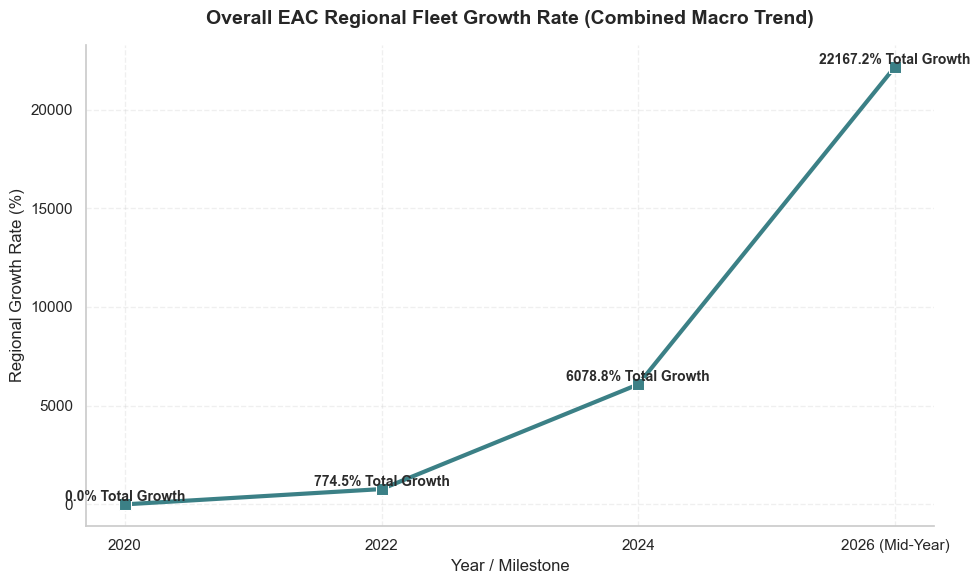

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate the entire region's fleet stocks per column year
total_2020 = growth['2020 Stock'].sum()
total_22 = growth['2022 Stock'].sum()
total_24 = growth['2024 Stock'].sum()
total_26 = growth['2026 Stock (Mid-Year)'].sum()

base_regional = total_2020 if total_2020 > 0 else 1

# Build data tracking the combined macro growth curve percentages
regional_trends = pd.DataFrame({
    'Milestone': ['2020', '2022', '2024', '2026 (Mid-Year)'],
    'Growth Rate (%)': [
        0.0,
        ((total_22 - total_2020) / base_regional) * 100,
        ((total_24 - total_2020) / base_regional) * 100,
        ((total_26 - total_2020) / base_regional) * 100
    ]
})

plt.figure(figsize=(10, 6))

# Generate the main line plot
sns.lineplot(
    x='Milestone', 
    y='Growth Rate (%)', 
    data=regional_trends, 
    color='#3b8086',  # Soft, professional teal anchor color
    marker='s',       # Square markers
    linewidth=3, 
    markersize=9
)

# Explicitly overlay the precise global numbers on top of the nodes
for x, y in zip(range(len(regional_trends)), regional_trends['Growth Rate (%)']):
    plt.text(x, y + 1.5, f"{y:.1f}% Total Growth", ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2b2b2b')

# Styling
plt.title('Overall EAC Regional Fleet Growth Rate (Combined Macro Trend)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year / Milestone', fontsize=12)
plt.ylabel('Regional Growth Rate (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
sns.despine()
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. The Regional Fleet Is Growing Rapidly from a Modest Base:
The country-level table used here sums to 400 EVs in 2020, 3,498 in 2022, 24,715 in 2024, and 89,069 by mid-2026. That is roughly 22,167% cumulative growth from 2020, but the percentage is amplified by the very small starting stock.

#### 2. Growth Is Concentrated in a Few Markets:
Kenya and Uganda contribute 72,324 of the 89,069 listed mid-2026 vehicles. Regional growth therefore depends heavily on sustained uptake in these two markets.

### Strategic Policy Insights:

#### 1. Plan for Absolute Demand, Not Percentage Growth Alone:
Translate the growing vehicle base into forecasts for charging power, battery supply, service capacity, and trained technicians by corridor and vehicle segment.

#### 2. Reconcile Regional Totals:
The country-level table sums to 89,069 in 2026, while the separate comparison dataset reports 89,319. Resolve this 250-vehicle difference and document which source and cut-off date governs regional reporting.


In [92]:
africa=pd.read_csv('africa_ev_stock_growth.csv')
africa

,Year,Total Cumulative Africa EV Stock (units),Average Annual Growth Rate (%),Core Continental Growth Drivers & Market Triggers
0,2020,8500,Baseline,Primarily concentrated in luxury passenger veh...
1,2022,21000,57.1,First widespread commercial asset-financing pr...
2,2024,68000,111.4,The Ethiopia Shift: Ethiopia implements a worl...
3,2026,255000,150.8,The Assembly Boom: Localized production lines ...


In [93]:
africa.columns

Index(['Year', 'Total Cumulative Africa EV Stock (units)',
       'Average Annual Growth Rate (%)',
       'Core Continental Growth Drivers & Market Triggers'],
      dtype='object')

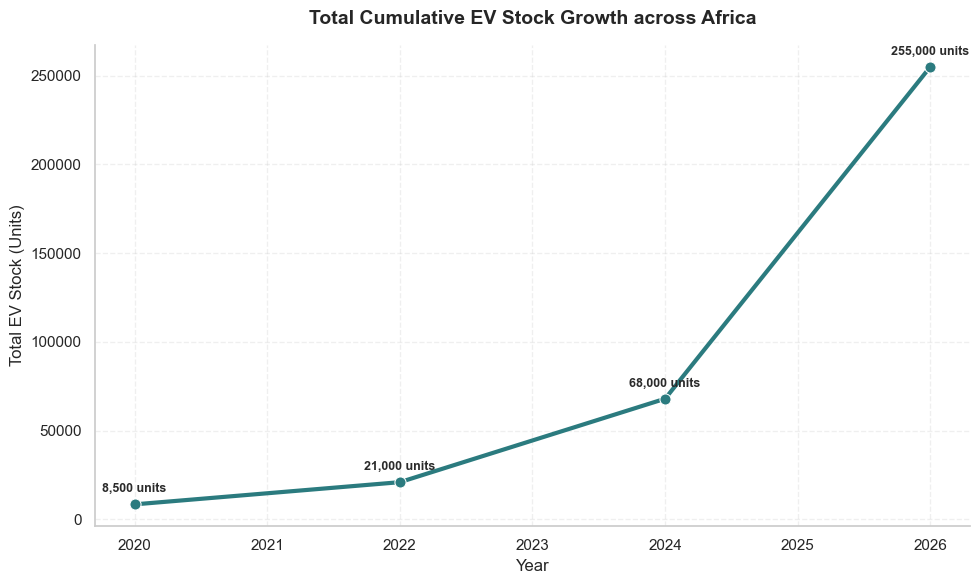

In [94]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Ensure the year column is sorted chronologically for line continuity
africa_sorted = africa.sort_values(by='Year')

# Generate the line plot for Cumulative Fleet Stock
sns.lineplot(
    x='Year', 
    y='Total Cumulative Africa EV Stock (units)', 
    data=africa_sorted, 
    color='#2b7b7f',  # Appeasing teal anchor color
    marker='o',       # Circular data points
    linewidth=3, 
    markersize=8
)

# Overlay precise unit counts on top of each annual node
for x, y in zip(africa_sorted['Year'], africa_sorted['Total Cumulative Africa EV Stock (units)']):
    plt.text(x, y + (africa_sorted['Total Cumulative Africa EV Stock (units)'].max() * 0.02), 
             f"{int(y):,} units", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#2b2b2b')

# Labels and layout styling
plt.title('Total Cumulative EV Stock Growth across Africa', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total EV Stock (Units)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
# Handle X-axis ticks cleanly if years are integers
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
sns.despine()
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Africa?s Estimated EV Stock Accelerates Sharply:
The dataset rises from 8,500 vehicles in 2020 to 255,000 in 2026?about a 30-fold increase. The largest absolute step is from 68,000 in 2024 to 180,000 in 2025, coinciding in the source notes with a period of expanded assembly and market activity.

#### 2. The Curve Signals Momentum, Not Uniform Readiness:
A continent-wide cumulative total does not show which countries, vehicle classes, or charging networks account for growth. Nor does it imply equal electricity or service capacity across markets.

### Strategic Policy Insights:

#### 1. Convert Stock Projections into Infrastructure Scenarios:
Use low, central, and high adoption cases to plan depot charging, public charging, battery swapping, grid reinforcement, and technician training.

#### 2. Validate Estimates and Definitions:
Confirm whether the series includes two- and three-wheelers, hybrids, and unregistered fleets, and keep those definitions stable when comparing years.


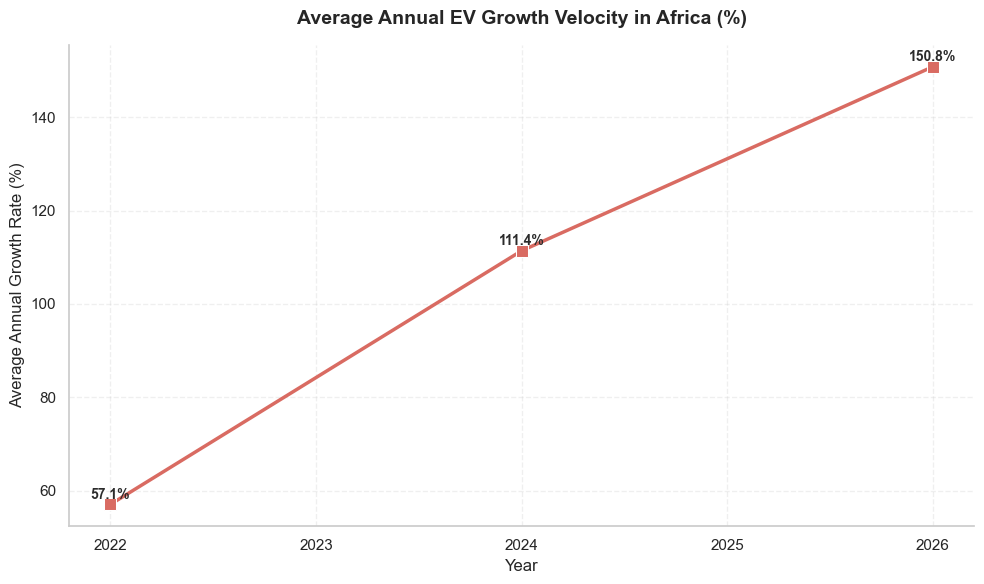

In [96]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(10, 6))

# 1. Clean the columns by forcing them to numeric values
# (This strips out any accidental spaces or hidden text characters)
africa['Year'] = pd.to_numeric(africa['Year'], errors='coerce')
africa['Average Annual Growth Rate (%)'] = pd.to_numeric(africa['Average Annual Growth Rate (%)'], errors='coerce')

# Drop any rows that couldn't be converted properly
africa_clean = africa.dropna(subset=['Year', 'Average Annual Growth Rate (%)'])

# 2. Sort explicitly in ASCENDING order based on the Year
africa_sorted = africa_clean.sort_values(by='Year', ascending=True)

# 3. Generate the line plot for Growth Rates
sns.lineplot(
    x='Year', 
    y='Average Annual Growth Rate (%)', 
    data=africa_sorted, 
    color='#d96b62',  # Soft, appealing clay/rose color
    marker='s',       # Square data points
    linewidth=2.5, 
    markersize=8
)

# 4. Overlay the exact percentage tags on top of each node safely
for x, y in zip(africa_sorted['Year'], africa_sorted['Average Annual Growth Rate (%)']):
    plt.text(
        x, 
        y + 0.5, 
        f"{float(y):.1f}%", 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold', 
        color='#2b2b2b'
    )

# Labels and layout styling
plt.title('Average Annual EV Growth Velocity in Africa (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Annual Growth Rate (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)

# Force the X-axis labels to format cleanly as individual integers (years)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
sns.despine()
plt.tight_layout()

plt.show()



### Core Analytical Observations:

#### 1. Reported Annual Growth Velocity Rises through 2026:
The series lists average annual growth rates of 57.1% in 2022, 111.4% in 2024, and 150.8% in 2026. The fleet is expanding quickly, while the 2026 rate is based on a much larger accumulated stock than the early period.

#### 2. Percentage Growth and Market Size Tell Different Stories:
A high rate on a small base may represent fewer vehicles than a modest rate on a large one. The separate stock series rises from 8,500 to 255,000 over 2020?2026, making both absolute additions and rates important.

### Strategic Policy Insights:

#### 1. Size Investment to Stock and Utilization:
Use EV additions, charging sessions, vehicle mileage, and fleet segment?not percentage growth alone?to determine where infrastructure is needed.

#### 2. Monitor Adoption Drivers:
Track the effects of vehicle financing, import and tax policy, local production, fuel prices, and charging availability so growth assumptions can be updated.


In [97]:
strongholds = pd.read_csv('Africa_E-mobility_strongholds.csv')
strongholds

,Rank,Country,Estimated EV Stock (2026),Primary Vehicle Segment,Core Growth Driver & Policy,Primary Verifying Source
0,1,Ethiopia,115000,Passenger Cars & SUVs,Complete ban on internal combustion engine (IC...,UN Environment Programme (UNEP)
1,2,Kenya,39324,2-Wheelers & Buses,"Strong private VC funding, domestic assembly, ...",Africa E-Mobility Alliance (AfEMA)
2,3,Uganda,33000,2-Wheelers (e-Bodas),Mass asset-financing and regional battery-swap...,AfEMA Data Portal
3,4,Ghana,17000,Mixed Fleet & 2-Wheelers,Comprehensive import duty waivers paired with ...,International Energy Agency (IEA)
4,5,Egypt,14000,4-Wheel Passenger & Buses,Fuel subsidy cuts and complete customs duty ex...,AfEMA Sector Tracker
5,6,Tanzania,10000,3-Wheelers & 2-Wheelers,"Low competition, high margins on e-tuk-tuks, a...",AfEMA / UN-Habitat Study
6,7,Morocco,10000,High-Value Passenger Cars,Global automotive manufacturing supply chain a...,IEA Global EV Outlook
7,8,South Africa,8500,Premium Luxury BEVs,Emerging production rebates; massive surge in ...,NAAMSA Automotive Council
8,9,Rwanda,7172,2-Wheelers (e-Motos),Phasing out new ICE taxi registrations; 0% imp...,Rwanda Ministry of Infrastructure
9,10,Angola,3500,Mixed Passenger & Fleet,Government mandate pushing state-owned departm...,iChelaba Motor Reports


In [98]:
strongholds.columns

Index(['Rank', 'Country', 'Estimated EV Stock (2026)',
       'Primary Vehicle Segment', 'Core Growth Driver & Policy',
       'Primary Verifying Source'],
      dtype='object')

C:\Users\PC\AppData\Local\Temp\ipykernel_18448\814512774.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


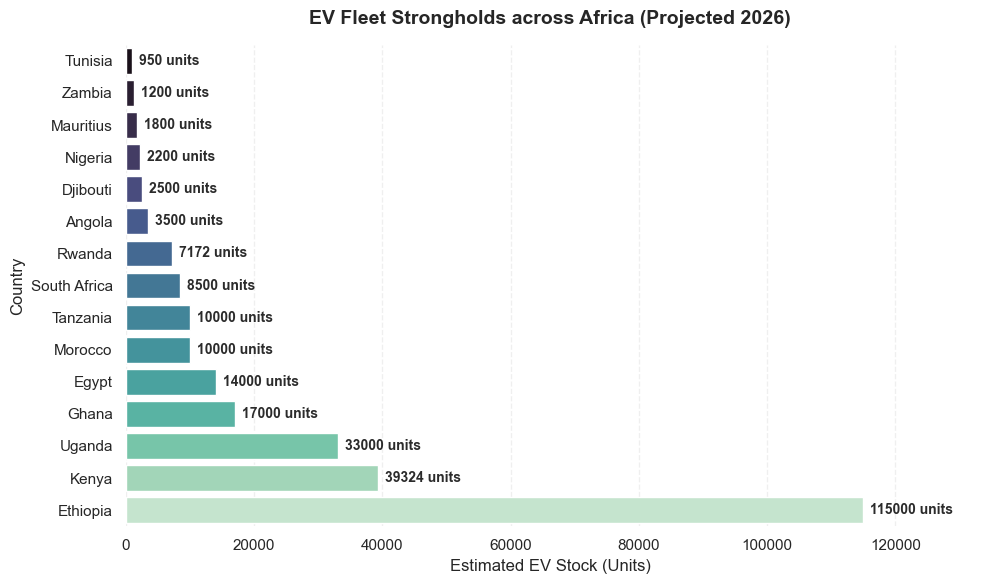

In [99]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(10, 6))

# Clean and convert the numeric column to prevent type mismatch errors
strongholds['Estimated EV Stock (2026)'] = pd.to_numeric(strongholds['Estimated EV Stock (2026)'], errors='coerce')
strongholds_clean = strongholds.dropna(subset=['Estimated EV Stock (2026)'])

# Sort by stock in ASCENDING order so the biggest strongholds sit prominently at the bottom/top
strongholds_sorted = strongholds_clean.sort_values(by='Estimated EV Stock (2026)', ascending=True)

# Generate a crisp, whisker-free horizontal bar chart
ax = sns.barplot(
    x='Estimated EV Stock (2026)', 
    y='Country', 
    data=strongholds_sorted, 
    palette='mako',
    errorbar=None  # Guarantees a perfectly clean visual without whiskers
)

# Render exact stock unit counters at the tip of every bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d units', padding=5, fontsize=10, fontweight='bold', color='#2b2b2b')

# Styling and layout configuration
plt.title('EV Fleet Strongholds across Africa (Projected 2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estimated EV Stock (Units)', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.xlim(0, strongholds_sorted['Estimated EV Stock (2026)'].max() * 1.15)  # Add label breathing room
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Ethiopia Leads the Listed African Strongholds:
The 2026 estimates place Ethiopia at 115,000 EVs, followed by Kenya at 39,324 and Uganda at 33,000. Tanzania is listed at 10,000 and Rwanda at 7,172.

#### 2. EAC Markets Have Distinct Commercial Niches:
The source associates Kenya and Uganda with two-wheelers, Tanzania with two- and three-wheelers, and Rwanda with e-motorcycles. Those segments imply different charging, swapping, and servicing needs.

#### 3. Estimates Differ Across the Notebook:
Rwanda?s 7,172 stronghold estimate differs from the 6,500 in the EAC stock table; Tanzania?s 10,000 matches its listed 2026 figure. Dates and coverage may not be identical.

### Strategic Policy Insights:

#### 1. Translate Stronghold Rankings into Corridor Partnerships:
Coordinate vehicle assembly, finance, charging, and service networks across neighboring markets to support cross-border fleet operations.

#### 2. Label Rankings as Estimates:
Publish cut-off dates, vehicle definitions, and source methodology so the rankings are not mistaken for a harmonized administrative census.


In [101]:
glob = pd.read_csv('Global_Emobility.csv')
glob

,Rank,Country/Territory,Estimated Annual EV Sales,Estimated Cumulative EV Fleet Stock,Primary Volume Segments,Explicit Institutional Data Sources
0,1,China,13750000,48500000,"Mass-market passenger cars, SUVs, and heavy el...",IEA Global EV Outlook / CAAM (China Associatio...
1,2,United States,1500000,6200000,"Premium SUVs, large sedans, and light-duty pic...",IEA Data Explorer / Argonne National Laborator...
2,3,Germany,570000,3400000,Enterprise corporate fleets and executive prem...,Ember EV Tracker / KBA (Kraftfahrt-Bundesamt F...
3,4,United Kingdom,550000,2300000,Company fleet leases and compact urban crossov...,Ember EV Tracker / SMMT (Society of Motor Manu...
4,5,France,450000,1900000,"Hatchbacks and localized low-income ""social le...",IEA Global EV Outlook / CCFA (Comité des Const...
5,6,India,150000,1500000,Note: Crosses 4.5M+ units if 2-wheelers and 3-...,Siam India / Ministry of Road Transport & High...
6,7,Norway,115000,1100000,High-penetration passenger cars (97% of all ne...,Our World in Data / OFV (Opplysningsrådet for ...
7,8,South Korea,140000,850000,Tech-dense domestic sedans and light commercia...,IEA Data Explorer / KAMA (Korea Automobile Man...
8,9,Canada,135000,780000,Cold-weather rated AWD crossovers concentrated...,Ember EV Tracker / Statistics Canada (StatCan)...
9,10,Netherlands,82000,690000,Premium compact hatchbacks backed by the dense...,IEA Global EV Outlook / RVO (Netherlands Enter...


In [102]:
glob.columns

Index(['Rank', 'Country/Territory', 'Estimated Annual EV Sales',
       'Estimated Cumulative EV Fleet Stock', 'Primary Volume Segments',
       'Explicit Institutional Data Sources'],
      dtype='object')

C:\Users\PC\AppData\Local\Temp\ipykernel_18448\2321713238.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


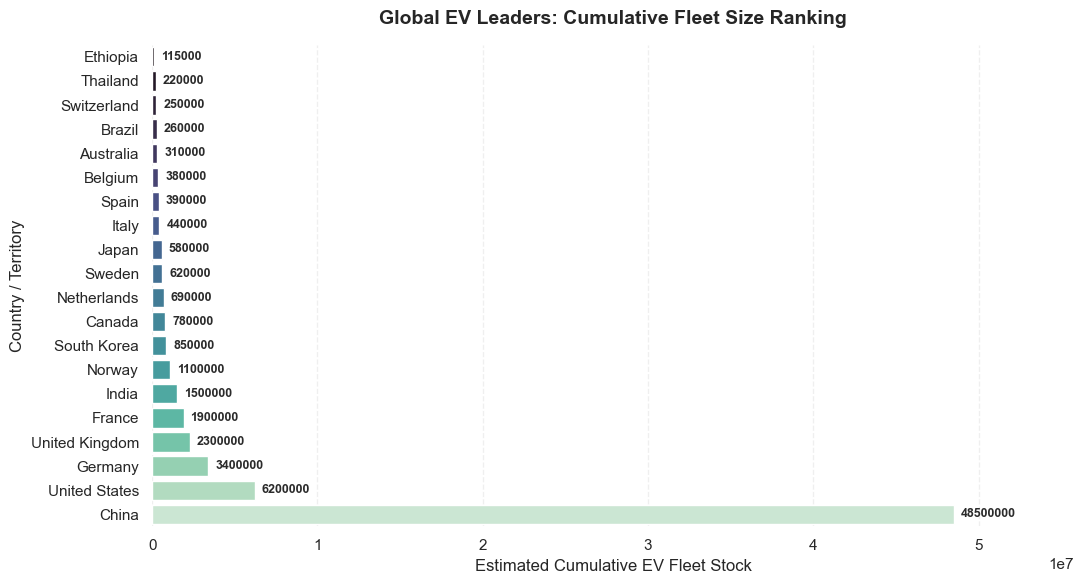

In [103]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(11, 6))

# 1. Convert columns to numeric types safely to avoid string errors
glob['Estimated Cumulative EV Fleet Stock'] = pd.to_numeric(glob['Estimated Cumulative EV Fleet Stock'], errors='coerce')
glob_clean = glob.dropna(subset=['Estimated Cumulative EV Fleet Stock'])

# 2. Sort by volume in ascending order so leaders anchor cleanly
glob_sorted = glob_clean.sort_values(by='Estimated Cumulative EV Fleet Stock', ascending=True)

# 3. Generate a clean horizontal bar plot with no whiskers
ax = sns.barplot(
    x='Estimated Cumulative EV Fleet Stock', 
    y='Country/Territory', 
    data=glob_sorted, 
    palette='mako',
    errorbar=None
)

# 4. Print structured numbers at the tips of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=5, fontsize=9, fontweight='bold', color='#2b2b2b')

# Labels and styling
plt.title('Global EV Leaders: Cumulative Fleet Size Ranking', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estimated Cumulative EV Fleet Stock', fontsize=12)
plt.ylabel('Country / Territory', fontsize=12)
plt.xlim(0, glob_sorted['Estimated Cumulative EV Fleet Stock'].max() * 1.15) # Headroom for text labels
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. The Global Fleet Is Highly Concentrated:
China leads the listed cumulative stock at 48.5 million, far ahead of the United States at 6.2 million and Germany at 3.4 million. The EAC markets are at a much earlier scale of deployment.

#### 2. Market Structure Varies by Country:
The table describes different dominant segments, from China?s passenger vehicles and buses to India?s large two- and three-wheeler market. Global comparisons therefore depend on which vehicle types are included.

### Strategic Policy Insights:

#### 1. Adapt Lessons, Do Not Copy Scale:
For the EAC, the most transferable practices are likely financing models, reliable charging, local servicing, and segment-appropriate policy?not the infrastructure scale of leading markets.

#### 2. Harmonize the Comparison Basis:
State whether the stock includes plug-in hybrids, two-wheelers, and commercial vehicles, and align reporting years before benchmarking against global leaders.


C:\Users\PC\AppData\Local\Temp\ipykernel_18448\2570848744.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


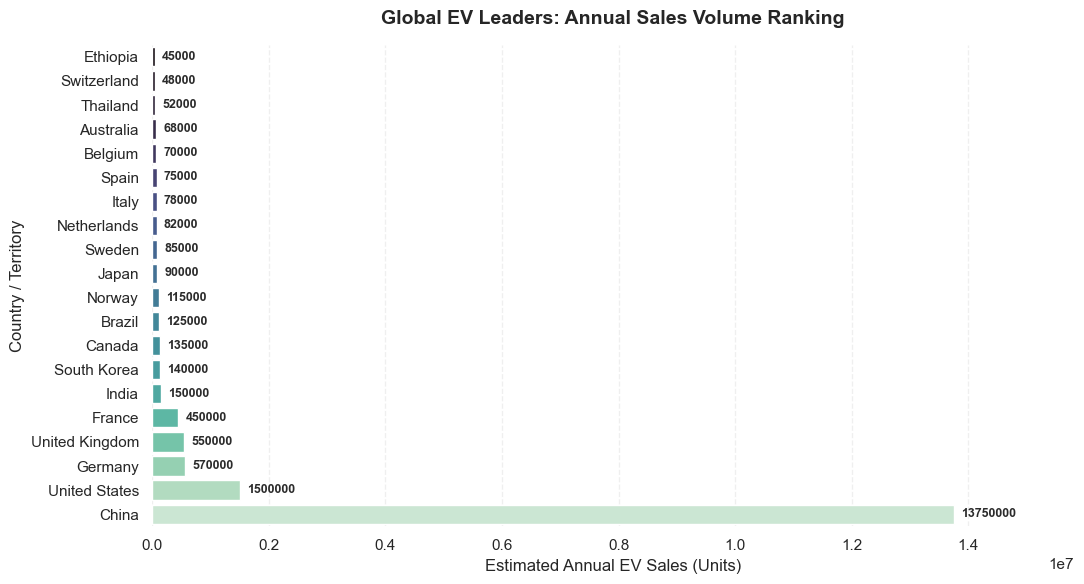

In [105]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(11, 6))

# 1. Convert columns to numeric types safely to avoid string errors
glob['Estimated Annual EV Sales'] = pd.to_numeric(glob['Estimated Annual EV Sales'], errors='coerce')
glob_clean = glob.dropna(subset=['Estimated Annual EV Sales'])

# 2. Sort by annual sales in ascending order for a clean waterfall presentation layout
glob_sorted = glob_clean.sort_values(by='Estimated Annual EV Sales', ascending=True)

# 3. Generate a clean horizontal bar plot with no whiskers using the appeasing 'mako' palette
ax = sns.barplot(
    x='Estimated Annual EV Sales', 
    y='Country/Territory', 
    data=glob_sorted, 
    palette='mako',
    errorbar=None  # Completely removes whiskers
)

# 4. Print clean data value labels at the tip of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=5, fontsize=9, fontweight='bold', color='#2b2b2b')

# Labels and styling
plt.title('Global EV Leaders: Annual Sales Volume Ranking', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estimated Annual EV Sales (Units)', fontsize=12)
plt.ylabel('Country / Territory', fontsize=12)
plt.xlim(0, glob_sorted['Estimated Annual EV Sales'].max() * 1.15) # Add headroom for the text labels
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)  # Clean borderless look
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. China Dominates Reported Annual EV Sales:
China is listed at 13.75 million annual sales, compared with 1.5 million in the United States and 570,000 in Germany. The gap illustrates the scale difference between a mature mass market and emerging EAC markets.

#### 2. Annual Sales and Cumulative Stock Are Different Measures:
Sales show current market flow; cumulative stock determines the in-use fleet that needs charging and maintenance. Both are required for market comparisons and infrastructure planning.

### Strategic Policy Insights:

#### 1. Benchmark Enabling Conditions:
Compare policy stability, access to finance, vehicle supply, charging availability, and after-sales service?not just sales totals.

#### 2. Avoid Direct Forecast Extrapolation:
Global market growth rates cannot be transferred directly to the EAC without accounting for income, vehicle mix, import costs, grid conditions, and local commercial use cases.


In [107]:
comparisons = pd.read_csv('global_africa_eac_ev_trends.csv')
comparisons

,Year,Global Cumulative Stock,Global Year-on-Year Growth (%),Total Africa Cumulative Stock,Africa Year-on-Year Growth (%),EAC Bloc Cumulative Stock,EAC Year-on-Year Growth (%),Key Structural Driver of the Year
0,2020,10000000,Baseline,8500,Baseline,600,Baseline,Early regional pilots vs. global subsidy booms.
1,2021,16500000,65.0,12000,41.2,1200,100.0,Global sales double; early asset-financing tri...
2,2022,26000000,57.6,21000,75.0,3518,193.2,Grid operators in East Africa introduce dedica...
3,2023,42000000,61.5,38000,81.0,9800,178.6,Localized battery-swapping networks deploy at ...
4,2024,58000000,38.1,68000,78.9,24715,152.2,The Ethiopia Mandate: Ethiopia bans ICE car im...
5,2025,77000000,32.8,180000,164.7,72000,191.3,"The Uganda Boom: Uganda deploys over 30,000 fi..."
6,2026,88500000,14.9,255000,41.7,89319,24.1,Market maturation; standardisation of VAT and ...


In [108]:
comparisons.columns

Index(['Year', 'Global Cumulative Stock', 'Global Year-on-Year Growth (%)',
       'Total Africa Cumulative Stock', 'Africa Year-on-Year Growth (%)',
       'EAC Bloc Cumulative Stock', 'EAC Year-on-Year Growth (%)',
       'Key Structural Driver of the Year'],
      dtype='object')

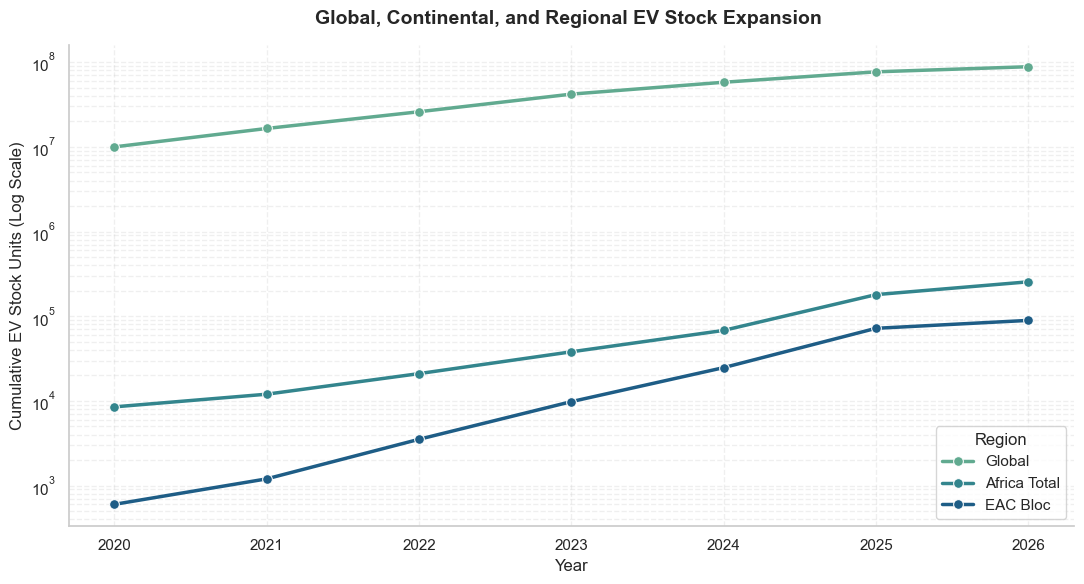

In [110]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

# 1. Clean the Year column (replace 'baseline' or 'Baseline' string with 2020)
comp_clean = comparisons.copy()
comp_clean['Year'] = comp_clean['Year'].astype(str).str.lower().str.strip()
comp_clean['Year'] = comp_clean['Year'].replace('baseline', '2020')
comp_clean['Year'] = pd.to_numeric(comp_clean['Year'], errors='coerce')

# Convert metrics to numeric numbers
metrics = ['Global Cumulative Stock', 'Total Africa Cumulative Stock', 'EAC Bloc Cumulative Stock']
for col in metrics:
    comp_clean[col] = pd.to_numeric(comp_clean[col], errors='coerce')

comp_clean = comp_clean.dropna(subset=['Year'] + metrics)
comp_sorted = comp_clean.sort_values(by='Year', ascending=True)

# 2. Reshape to long format for Seaborn line plotting
melted_stock = comp_sorted.melt(
    id_vars=['Year'], 
    value_vars=metrics, 
    var_name='Region', 
    value_name='Stock Volume'
)

# Clean legend labels
label_map = {
    'Global Cumulative Stock': 'Global',
    'Total Africa Cumulative Stock': 'Africa Total',
    'EAC Bloc Cumulative Stock': 'EAC Bloc'
}
melted_stock['Region'] = melted_stock['Region'].map(label_map)

# 3. Plot the trajectories
sns.lineplot(
    x='Year', y='Stock Volume', hue='Region', data=melted_stock,
    palette='crest', marker='o', linewidth=2.5, markersize=7
)

# Format axes
plt.yscale('log')
plt.title('Global, Continental, and Regional EV Stock Expansion ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Cumulative EV Stock Units (Log Scale)', fontsize=12)
plt.grid(True, which="both", linestyle='--', alpha=0.3)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
sns.despine()
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. All Three Regions Expand, but at Very Different Scales:
The comparison dataset reports 2026 cumulative stocks of 88.5 million globally, 255,000 for Africa, and 89,319 for the EAC. The logarithmic axis makes these trajectories visible together despite the large scale differences.

#### 2. The EAC Represents a Meaningful Share of the Reported African Total:
The stated EAC total is about 35% of the African total in 2026, compared with about 7% in 2020. This is a strong reported increase, but should be checked against harmonized national data before drawing regional market-share conclusions.

### Strategic Policy Insights:

#### 1. Align Regional Planning with the Market?s Actual Scale:
Use scenarios for grid upgrades, public corridors, and fleet depots rather than scaling infrastructure in proportion to global stock.

#### 2. Reconcile the EAC Series with Country Totals:
This dataset reports 89,319 EAC vehicles in 2026, while the country-level growth table sums to 89,069. Resolve scope and cut-off-date differences before policy targets are set.


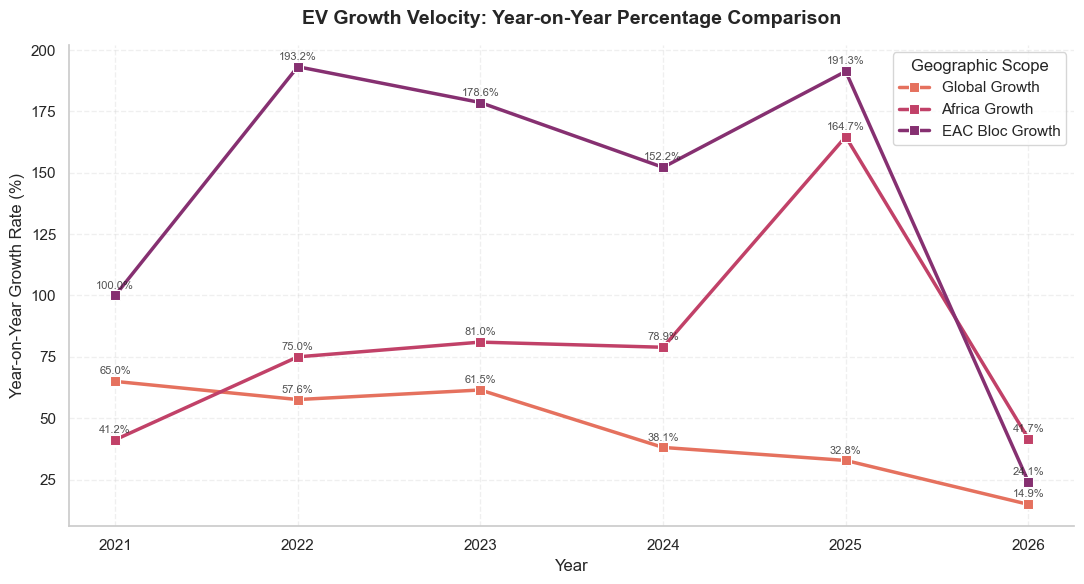

In [111]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

growth_cols = ['Global Year-on-Year Growth (%)', 'Africa Year-on-Year Growth (%)', 'EAC Year-on-Year Growth (%)']
for col in growth_cols:
    comp_sorted[col] = pd.to_numeric(comp_sorted[col], errors='coerce')

# Melt data for visualization grouping
melted_growth = comp_sorted.melt(
    id_vars=['Year'], 
    value_vars=growth_cols, 
    var_name='Geographic Scope', 
    value_name='YoY Growth (%)'
)

growth_label_map = {
    'Global Year-on-Year Growth (%)': 'Global Growth',
    'Africa Year-on-Year Growth (%)': 'Africa Growth',
    'EAC Year-on-Year Growth (%)': 'EAC Bloc Growth'
}
melted_growth['Geographic Scope'] = melted_growth['Geographic Scope'].map(growth_label_map)

# Generate trendlines
sns.lineplot(
    x='Year', y='YoY Growth (%)', hue='Geographic Scope', data=melted_growth,
    palette='flare', marker='s', linewidth=2.5, markersize=7
)

# Text marker values directly on nodes
for scope in melted_growth['Geographic Scope'].unique():
    subset = melted_growth[melted_growth['Geographic Scope'] == scope]
    for x, y in zip(subset['Year'], subset['YoY Growth (%)']):
        if not pd.isna(y) and y > 0:  # Skip baseline zero points to keep canvas uncluttered
            plt.text(x, y + 2, f"{y:.1f}%", ha='center', va='bottom', fontsize=8, alpha=0.8)

plt.title('EV Growth Velocity: Year-on-Year Percentage Comparison', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Year-on-Year Growth Rate (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
sns.despine()
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. EAC Growth Exceeded the Global and African Rates through 2025:
The dataset reports EAC year-on-year growth of 100% in 2021, then 193.2%, 178.6%, 152.2%, and 191.3% from 2022 to 2025. Each is higher than the corresponding global rate. This signals rapid expansion from a small regional base, not a larger fleet than the global or continental markets.

#### 2. Reported Growth Slows Sharply in 2026:
The 2026 rates fall to 24.1% for the EAC, 41.7% for Africa, and 14.9% globally. The EAC remains the fastest-growing of the three in 2026, but the slowdown is substantial compared with its 2025 rate.

#### 3. Growth Rates Depend on Consistent Coverage:
These figures are only comparable if vehicle categories, registration coverage, and the status of each year's data (actual, provisional, or estimated) are consistent. A small starting stock can also make percentage growth look especially dramatic.

### Strategic Policy Insights:

#### 1. Plan Infrastructure Around Absolute Additions and Utilization:
Convert the stock increase into expected charging sessions, power demand, and battery-service capacity by country, vehicle segment, and corridor. Use vehicle registrations and charger utilization to update those estimates.

#### 2. Use Flexible Investment Scenarios:
The 2026 slowdown argues against extrapolating earlier triple-digit rates indefinitely. Phase charging deployment and grid upgrades against low, central, and high uptake cases.

#### 3. Improve the Regional Market Tracker:
Label years as observed or estimated and harmonize reporting definitions across partner states before using growth rates to set targets or allocate investment.

C:\Users\PC\AppData\Local\Temp\ipykernel_18448\424487259.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_18448\424487259.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


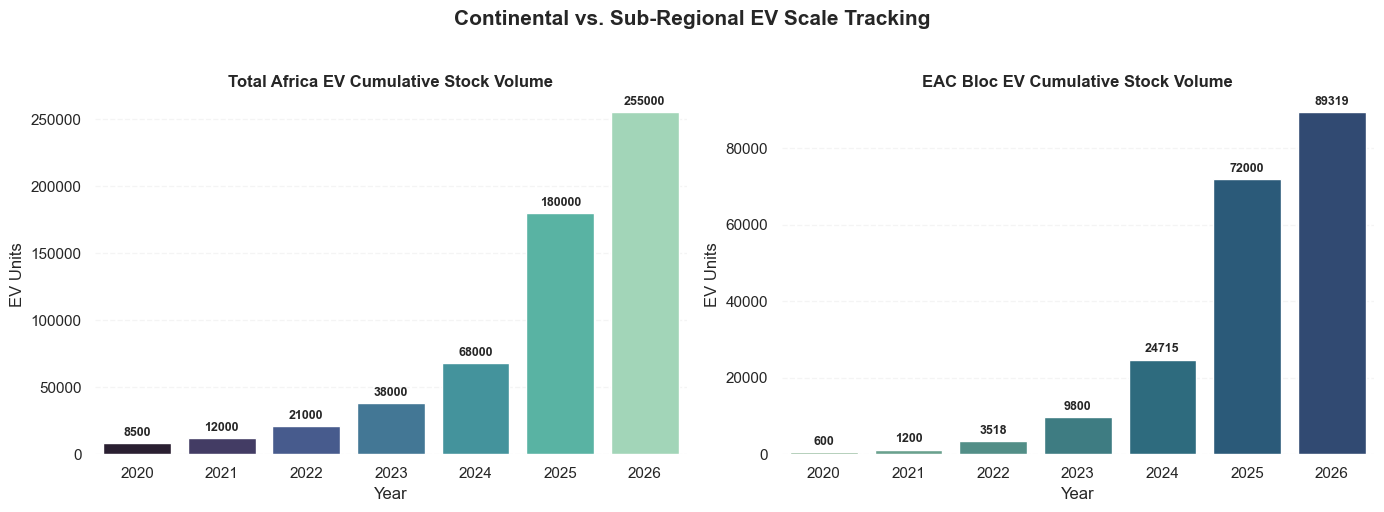

In [112]:
import seaborn as sns
import matplotlib.pyplot as plt

# Setup clean 1x2 subplot grid
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Plot A: Total Africa Market
sns.barplot(
    x='Year', y='Total Africa Cumulative Stock', data=comp_sorted,
    palette='mako', errorbar=None, ax=axes[0]
)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3, fontsize=9, fontweight='bold')
axes[0].set_title('Total Africa EV Cumulative Stock Volume', fontsize=12, fontweight='bold')
axes[0].set_ylabel('EV Units')

# Plot B: East Africa Market Share
sns.barplot(
    x='Year', y='EAC Bloc Cumulative Stock', data=comp_sorted,
    palette='crest', errorbar=None, ax=axes[1]
)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', padding=3, fontsize=9, fontweight='bold')
axes[1].set_title('EAC Bloc EV Cumulative Stock Volume', fontsize=12, fontweight='bold')
axes[1].set_ylabel('EV Units')

# Shared layout settings
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.2)
    ax.set_xlabel('Year')
    sns.despine(ax=ax, left=True, bottom=True)

plt.suptitle('Continental vs. Sub-Regional EV Scale Tracking', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

plt.show()


### Core Analytical Observations:

#### 1. Both African and EAC EV Stocks Have Expanded Rapidly:
The comparison series reports Africa's cumulative stock rising from 8,500 in 2020 to 255,000 in 2026, a 30-fold increase. The EAC rises from 600 to 89,319 over the same period, nearly 149-fold. The EAC's greater relative growth starts from a much smaller base.

#### 2. The EAC's Reported Share of African Stock Has Increased:
The EAC accounts for about 7.1% of the African total in 2020 and 35.0% in 2026 in this dataset. This suggests East Africa is an important contributor to the continent's recorded e-mobility expansion, while remaining much smaller than the continental market in absolute terms.

#### 3. Regional Totals Need Reconciliation:
The EAC comparison series gives 89,319 vehicles for 2026, while the separate partner-state growth table sums to 89,069. The 250-vehicle difference should be resolved or documented before these totals are used as official targets.

### Strategic Policy Insights:

#### 1. Convert Fleet Growth into Corridor-Level Charging Plans:
Use the growing EAC stock to estimate charging demand by vehicle type, operating hours, and route. Prioritize high-utilization fleet depots and transport corridors, and check local grid capacity before expanding public charging.

#### 2. Maintain a Harmonized Regional EV Registry:
Align definitions, reporting cut-off dates, and treatment of two-wheelers, three-wheelers, buses, and other EVs across national datasets. Publish revisions when country estimates change.

#### 3. Track Access and Reliability Alongside Stock:
Monitor charger locations, uptime, energy delivered, and geographic coverage together with vehicle counts. Stock growth alone does not show whether charging infrastructure is keeping pace or serving rural and lower-access communities.